# Cuaderno de funciones: optimización no supervisada de hiperparámetros en el borde

En este cuaderno explico **cada función del proyecto**: para qué la escribí y cómo funciona. Debajo de casi
todas hay una celda que la ejecuta con un ejemplo pequeño. Es el anexo de `tesis_pipeline.ipynb`, que muestra el
experimento completo con los datos reales.

**Datos de los ejemplos.** Uso datos **sintéticos** (los genera `tests/make_synthetic_toniot.py`) y escribo todo
en una **carpeta temporal**. El cuaderno no lee ni modifica `data/`, `outputs/` ni `Datasets/`, así que se puede
ejecutar sin miedo. Las excepciones son dos: el gráfico de la Parte 1 lee los tamaños reales de la versión 2
(`data/splits_v2`), y la Parte L lee los bloques de la versión 1 para medir el problema de los flujos repetidos.

## Orden de ejecución del proyecto

| Paso | Archivo | Qué hace | Dónde se corre |
|---|---|---|---|
| | `run_all.py` | corre los pasos en orden | PC / Raspberry |
| 0 | `scripts/0_check_env.py` | revisa las bibliotecas | PC / Raspberry |
| 0 | `scripts/0_configurar_preprocessor.py` + preprocesador (pasos 00 a 02) | CSV de TON_IoT → Parquet | PC |
| 1 | `src/1_prepare_splits.py` | bloques train / val / test_oracle / test_final | PC |
| 2 | `src/2_diagnose.py` | ¿las métricas sirven de guía? | PC |
| 3 | `src/3_optimize.py` | búsqueda con Optuna, oráculo y línea base | PC |
| 4 | `src/4_edge_benchmark.py` | latencia, CPU y RAM de cada modelo | Raspberry Pi 5 |
| 5 | `src/5_evaluate.py` | evaluación final en test_final | PC |
| 6 | `src/6_report.py` | tablas LaTeX | PC |

Los módulos de apoyo `common.py`, `detectors.py`, `objectives.py` y `search_space.py` no llevan número porque los
importan los demás scripts, y Python no permite importar un archivo cuyo nombre empieza con un dígito
(`import 1_prepare_splits` es un error de sintaxis). Por eso aquí cargo los scripts numerados con
`importlib.import_module("1_prepare_splits")`.

## Índice

**Primero, el porqué (con ejemplos):**
- **Parte 0.** Ideas básicas: flujo, etiqueta, detector, umbral, hiperparámetro y fuga de información
- **Parte 1.** El viaje completo de los datos (diagrama y tamaños reales)
- **Parte 2.** El preprocesador, paso a paso con una tabla de 12 flujos
- **Parte 3.** Cómo parto los datos y por qué (8 pasos)
- **Parte 4.** Cómo elijo cada cosa: umbral, hiperparámetros, modelo final y "mejora"

**Después, la referencia función por función:**
- **A.** `run_all.py`: el orquestador
- **B.** `scripts/`: preparar el entorno
- **C.** `common.py`: utilidades que usan todas las etapas
- **D.** `1_prepare_splits.py`: los bloques de datos
- **E.** `search_space.py`, `detectors.py`, `objectives.py`: qué se busca, los detectores y las métricas
- **F.** `2_diagnose.py`: diagnóstico de las métricas
- **G.** `3_optimize.py`: la búsqueda de hiperparámetros
- **H.** `4_edge_benchmark.py`: costo en el dispositivo de borde
- **I.** `5_evaluate.py`: evaluación final
- **J.** `6_report.py`: tablas para la memoria
- **K.** `tests/`: pruebas con datos sintéticos
- **L.** Revisión del preprocesador (el problema de los flujos repetidos)

## Preparación del cuaderno

Agrego `src/`, `scripts/` y `tests/` a la ruta de Python, creo una carpeta temporal con datos sintéticos y armo
una configuración de prueba que apunta a esa carpeta, con pocos intentos para que todo corra en un par de minutos.

La función `correr(modulo, *args)` ejecuta el `main()` de un script como si lo llamara desde la terminal:
`python src/<script>.py --config <yaml de prueba> <args>`.

In [1]:
import importlib
import json
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
if not (RAIZ / "src").exists():          # por si el cuaderno se abre desde otra carpeta
    RAIZ = RAIZ.parent
for sub in ("src", "scripts", "tests"):
    sys.path.insert(0, str(RAIZ / sub))

import common
import detectors
import objectives
import search_space
import make_synthetic_toniot as syn
ps = importlib.import_module("1_prepare_splits")

# Bloques REALES (solo los leo, para mostrar cifras reales)
REAL = RAIZ / "data" / "splits_v2"      # versión 2 (la de la memoria)
HAY_REAL = (REAL / "manifest.json").exists()
MAN_REAL = common.load_json(REAL / "manifest.json") if HAY_REAL else None

# Carpeta temporal: aqui escribo todo lo que generan los ejemplos
TMP = Path(tempfile.mkdtemp(prefix="cuaderno_"))
syn.write(TMP / "Datasets")              # datos sinteticos con el formato del preprocesador

# Configuracion de prueba: se mezcla encima de config/experiment.yaml
prueba = {
    "paths": {"datasets_root": str(TMP / "Datasets"), "splits_dir": str(TMP / "splits"),
              "outputs_dir": str(TMP / "outputs")},
    "input": {"variant": "stratified"},
    "detectors": {"iforest": ["silhouette", "davies_bouldin"]},
    "optimization": {"n_trials": 5, "seeds": [42, 43], "top_k": 2, "latency_samples": 10},
    "edge": {"n_inference_runs": 50, "n_warmup_runs": 5},
    "autoencoder": {"backend": "sklearn"},
}
CFG_PATH = TMP / "prueba.yaml"
CFG_PATH.write_text(yaml.safe_dump(prueba), encoding="utf-8")
cfg = common.load_config(CFG_PATH)


def correr(modulo, *args, con_config=True):
    """Ejecuta modulo.main() como si se llamara desde la terminal."""
    viejo = sys.argv
    sys.argv = [modulo.__name__ + ".py", *(["--config", str(CFG_PATH)] if con_config else []), *args]
    try:
        modulo.main()
    except SystemExit as e:              # argparse o sys.exit: no detiene el cuaderno
        if e.code not in (None, 0):
            print("SystemExit:", e.code)
    finally:
        sys.argv = viejo


print("Carpeta temporal:", TMP)

Carpeta temporal: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i


---
# Parte 0. Ideas básicas

Antes de mirar el código conviene tener claras siete ideas. Cada una va con un ejemplo cotidiano.

### 1. Un flujo es una fila de la tabla
Cada fila de TON_IoT es una "conversación" entre dos equipos de la red: cuánto duró (`duration`), cuántos bytes
mandó cada lado (`src_bytes`, `dst_bytes`), qué protocolo usó (`proto`: tcp, udp...), etc. Las columnas que
describen el flujo son las **variables** (*features*).

### 2. Cada flujo tiene una etiqueta: normal o ataque
- `label` = 0 (normal) o 1 (ataque).
- `type` = qué ataque es: `ddos`, `scanning`, `password`, `xss`, `mitm`... o `normal`.

En una red real nadie entrega la etiqueta. Por eso los detectores de mi tesis son **no supervisados**: aprenden
sin etiquetas.

### 3. Un detector de anomalías aprende cómo es "lo normal"
> **Ejemplo:** un guardia que lleva meses en un edificio conoce a la gente que trabaja ahí. No necesita una
> lista de ladrones: le basta con notar a alguien que no se parece a lo habitual.

Por eso entreno los detectores **solo con tráfico normal**. Cada detector entrega un **puntaje** para cada
flujo: mientras más alto, más raro.

### 4. El umbral convierte el puntaje en una decisión
Si el puntaje supera el umbral, el flujo se marca como **ataque**. Fijo el umbral para que solo un 5 % del tráfico
normal lo supere (percentil q = 0,95). Es decir, acepto de antemano una tasa de falsas alarmas del 5 %.

### 5. Los hiperparámetros son las "perillas" de cada detector
Por ejemplo, cuántos árboles usa Isolation Forest o cuántos vecinos mira LOF. Mi tesis busca la mejor combinación
de perillas **sin usar etiquetas**, guiándose por métricas no supervisadas.

### 6. Fuga de información (*data leakage*): el error que todo el diseño quiere evitar
> **Ejemplo:** si un estudiante practica con las mismas preguntas que vendrán en la prueba, sacará buena nota
> aunque no haya aprendido. La nota no mide lo que sabe.

Si un modelo ve, directa o indirectamente, los datos con que después lo evalúo, su resultado sale mejor de lo que
es en realidad. Casi todas mis decisiones sobre cómo partir los datos existen para evitar esto.

### 7. ¿Por qué parto los datos en varios bloques?
Porque cada tarea necesita datos que no se usaron en la tarea anterior:

| Tarea | Necesita | Bloque |
|---|---|---|
| Aprender qué es normal | tráfico normal | `train` |
| Fijar el umbral | tráfico normal que el modelo no vio | `val` (mitad *calibración*) |
| Puntuar una configuración (métrica no supervisada) | tráfico normal distinto del anterior | `val` (mitad *objetivo*) |
| Calcular la cota superior (oráculo) | normal y ataques con etiqueta | `test_oracle` |
| Medir el resultado final, una sola vez | normal y ataques nunca usados | `test_final` |

---
# Parte 1. El viaje completo de los datos (versión 2)

```
 Train_Test_Network.csv  (TON_IoT original: 211 043 flujos, 76 % ataques)
          │
          │  PREPROCESADOR (versión 2)
          ├─ paso 00: crea la etiqueta normal / anormal
          ├─ paso 01: quita repetidos y ambiguos (quedan 93 455)
          ├─ paso 01: parte 80/20, estratificado ─────┐
          │                                           │
          ▼                                           ▼
   train (80 %)                               test (20 %)
   74 764 flujos                              18 691 flujos
          │  paso 02: log(1+x), escala 0–1, one-hot   │  (mismo escalado, aprendido del train)
          ▼                                           ▼
 ───────────────────────── 1_prepare_splits.py (este proyecto) ─────────────────────────
          │                                           │
   me quedo SOLO con los normales (18 926)            │
   los ataques los descarto                           │
          │                                           │
     ┌────┴─────┐                               ┌─────┴──────┐
     ▼          ▼                               ▼            ▼
  train 85 %   val 15 %                    test_oracle    test_final
  16 087       2 839                       9 343          9 348
  (entrenar)   │                           (oráculo)      (evaluación final, 1 vez)
               ├─ calibración 50 % → fija el umbral
               └─ objetivo    50 % → calcula la métrica no supervisada
```

La celda siguiente dibuja los tamaños reales de cada bloque. Los lee de `data/splits_v2/manifest.json` y no
modifica nada.

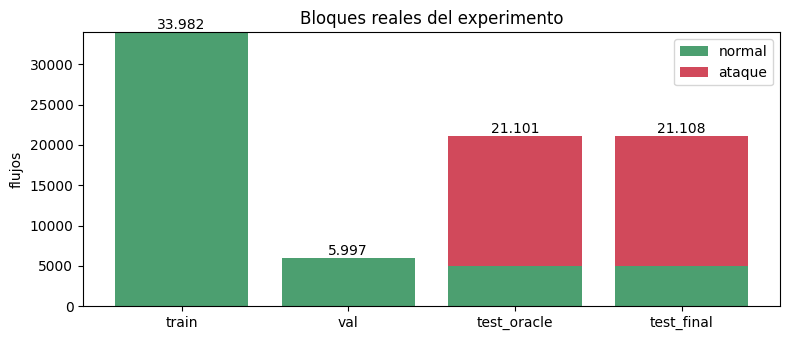

,normal,ataque
train,33982,0
val,5997,0
test_oracle,5010,16091
test_final,5011,16097


In [2]:
if HAY_REAL:
    s = MAN_REAL["splits"]
    bloques = ["train", "val", "test_oracle", "test_final"]
    normales = [s["train"]["rows"], s["val"]["rows"], s["test_oracle"]["normal"], s["test_final"]["normal"]]
    ataques = [0, 0, s["test_oracle"]["attack"], s["test_final"]["attack"]]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.bar(bloques, normales, label="normal", color="#4C9F70")
    ax.bar(bloques, ataques, bottom=normales, label="ataque", color="#D1495B")
    for i, (n, a) in enumerate(zip(normales, ataques)):
        ax.text(i, n + a, f"{n + a:,}".replace(",", "."), ha="center", va="bottom")
    ax.set_ylabel("flujos"); ax.set_title("Bloques reales del experimento (v2)"); ax.legend()
    plt.tight_layout(); plt.show()
    display(pd.DataFrame({"normal": normales, "ataque": ataques}, index=bloques))
else:
    print("Todavia no hay bloques reales en data/splits_v2/ (correr: python run_all.py --config config/experiment_v2.yaml --etapas preprocesar,splits)")

**Qué se ve en el gráfico:**
- `train` y `val` son completamente verdes: solo tráfico normal y **sin etiqueta guardada**.
- `test_oracle` y `test_final` tienen casi el mismo tamaño y **la misma mezcla** (74,7 % de ataques), porque
  los partí de forma estratificada (lo explico en la Parte 3, paso F).

---
# Parte 2. El preprocesador, paso a paso con un ejemplo pequeño

Para ver qué le pasa a cada fila uso una **mini-tabla de 12 flujos** inventados, con las mismas columnas que
TON_IoT (solo 3 variables, para que quepa en pantalla). Las celdas llaman a las **funciones reales** del
preprocesador, no a copias, así que lo que se ve es exactamente lo que hace su código.

Las filas **0, 3, 6 y 10** son idénticas. En TON_IoT esto pasa muchísimo (más de la mitad de las filas tiene una
gemela), y es la causa del problema principal que explico en la Parte L.

Esta parte muestra el preprocesador **tal como venía** (el de la v1). En la v2 le agregué tres cosas que menciono
en cada paso: quitar los flujos repetidos, estratificar la partición y aplicar log(1+x) a las variables numéricas.

In [3]:
# Las funciones del preprocesador se importan desde su carpeta
PRE = RAIZ / "preprocesador" / "preprocessor_v2"
for p in (PRE, PRE / "00_source_preprocessing"):
    sys.path.insert(0, str(p))

mini = pd.DataFrame({
    "duration":  [0.50, 1.20, 0.80, 0.50, 2.00, 0.01, 0.50, 0.01, 3.50, 0.90, 0.50, 0.03],
    "src_bytes": [300, 1200, 800, 300, 2500, 40, 300, 44, 9000, 700, 300, 60],
    "proto":     ["tcp", "tcp", "udp", "tcp", "tcp", "tcp", "tcp", "tcp", "tcp", "udp", "tcp", "icmp"],
    "label":     [0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1],
    "type":      ["normal"] * 5 + ["ddos", "normal", "scanning", "password", "normal", "normal", "scanning"],
})
mini

,duration,src_bytes,proto,label,type
0,0.50,300,tcp,0,normal
1,1.20,1200,tcp,0,normal
2,0.80,800,udp,0,normal
3,0.50,300,tcp,0,normal
4,2.00,2500,tcp,0,normal
5,0.01,40,tcp,1,ddos
6,0.50,300,tcp,0,normal
7,0.01,44,tcp,1,scanning
8,3.50,9000,tcp,1,password
9,0.90,700,udp,0,normal


## Paso 00: crear la etiqueta "normal / anormal"
**Qué hace:** TON_IoT trae la etiqueta como número (`label` = 0 o 1). El preprocesador trabaja con varios
datasets y necesita que todos usen el mismo formato, así que crea una columna nueva, `category`, con el texto
`normal` o `anormal`.

**Cómo:** fila por fila, si `label` es `0` (o `"normal"`) escribe `normal`; si no, `anormal`.

In [4]:
from ton_iot import TonIoTPreprocessor
paso00 = object.__new__(TonIoTPreprocessor)            # se crea sin leer archivos
paso00.info = {"normal_label": "normal", "anomaly_label": "anormal"}
mini00 = paso00.transform_chunk(mini)                  # <- funcion real del preprocesador
mini00[["label", "type", "category"]]

,label,type,category
0,0,normal,normal
1,0,normal,normal
2,0,normal,normal
3,0,normal,normal
4,0,normal,normal
5,1,ddos,anormal
6,0,normal,normal
7,1,scanning,anormal
8,1,password,anormal
9,0,normal,normal


## Paso 01: partir en train (80 %) y test (20 %)
**Qué hace:** separa las filas al azar: 80 % para entrenar y 20 % para probar.

**¿Por qué 80/20?** Es una proporción clásica: deja la mayor parte para aprender y suficiente para medir.

**¿Por qué al azar y con `random_state=42`?** Al azar, para que ambas partes se parezcan. Con una semilla fija
(42), para que siempre salga la misma partición y otra persona pueda repetir el experimento.

**¿Qué no hacía en la versión original?** No quitaba filas repetidas y no estratificaba (no forzaba a que cada tipo
de ataque quedara en la misma proporción en ambos lados). Con 12 filas, el 20 % son **3 filas**.

In [5]:
from sklearn.model_selection import train_test_split
tr_prof, te_prof = train_test_split(mini00, test_size=0.20, random_state=42)   # la misma llamada del paso 01
print("Filas que fueron a TRAIN:", sorted(tr_prof.index.tolist()))
print("Filas que fueron a TEST: ", sorted(te_prof.index.tolist()))

gemelas = [0, 3, 6, 10]
print("\nLas filas gemelas", gemelas, "quedaron así:")
for i in gemelas:
    print(f"   fila {i:2d} -> {'TRAIN' if i in tr_prof.index else 'TEST'}")

Filas que fueron a TRAIN: [1, 2, 3, 4, 5, 6, 7, 8, 11]
Filas que fueron a TEST:  [0, 9, 10]

Las filas gemelas [0, 3, 6, 10] quedaron así:
   fila  0 -> TEST
   fila  3 -> TRAIN
   fila  6 -> TRAIN
   fila 10 -> TEST


**Lo importante:** las filas gemelas pueden quedar a ambos lados. Entonces el test contiene un flujo idéntico a uno
que el modelo ya vio al entrenar. Es como poner en la prueba una pregunta que ya estaba en la guía de ejercicios:
el modelo "acierta" sin mérito. Con el preprocesador original esto le pasaba al **58 %** del test real. En la v2
el paso 01 quita los repetidos **antes** de partir, y el problema desaparece.

## Paso 02: escalar los números a 0–1 y convertir texto en columnas 0/1 (one-hot)

### a) Rellenar vacíos y escalar con MinMax
**Qué hace:** cada número se lleva a la escala 0–1 con la fórmula

$$x_{\text{nuevo}} = \frac{x - \text{mínimo}}{\text{máximo} - \text{mínimo}}$$

**¿Por qué?** `src_bytes` llega a miles y `duration` a segundos: sin escalar, la variable con números más grandes
"gritaría más fuerte" para el modelo.

**¿Por qué el mínimo y el máximo salen solo del train?** Para no espiar el test: si el test ayudara a decidir la
escala, ya se estaría usando información de la prueba. Los vacíos se rellenan con la media del train.

**Ejemplo con números:** si en el train `duration` va de 0,01 a 3,50, un flujo de 0,50 s queda en
(0,50 − 0,01) / (3,50 − 0,01) = **0,14**.

En la v2, antes del MinMax aplico log(1+x) a las variables numéricas. Bytes, paquetes y duración tienen colas muy
largas: unos pocos flujos enormes fijan el máximo y todos los demás quedan apretados cerca de 0.

### b) One-hot: convertir texto en columnas de 0 y 1
**Qué hace:** los modelos solo entienden números. Una columna de texto como `proto` (tcp / udp / icmp) se convierte
en **una columna por valor**: `proto_tcp`, `proto_udp`, `proto_icmp`, con 1 en la que corresponde.

| proto | → | proto_tcp | proto_udp | proto_icmp |
|---|---|---|---|---|
| tcp |  | 1 | 0 | 0 |
| udp |  | 0 | 1 | 0 |

La celda usa las funciones reales del paso 02 (`build_schema` y `process_chunk`).

In [6]:
p02 = importlib.import_module("02_preprocessing")
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

info_mini = {"label": "category", "normal_label": "normal", "anomaly_label": "anormal",
             "category_col": "label", "sub_category_col": "type", "id_cols": [],
             "numerical_cols": ["duration", "src_bytes"], "categorical_cols": ["proto"]}
num = info_mini["numerical_cols"]

# Igual que el main() del paso 02: estadisticas SOLO del train
minimos, maximos, medias = tr_prof[num].min(), tr_prof[num].max(), tr_prof[num].mean()
imputer = SimpleImputer(strategy="mean").fit(pd.DataFrame([medias]))
scaler = MinMaxScaler().fit(pd.DataFrame([minimos, maximos]))
print("mínimos del train:", minimos.to_dict(), "\nmáximos del train:", maximos.to_dict())

schema, columnas = p02.build_schema(tr_prof.copy(), info_mini)          # que columnas one-hot existen
te02 = p02.process_chunk(te_prof.copy(), info_mini, imputer, scaler, columnas)
tr02 = p02.process_chunk(tr_prof.copy(), info_mini, imputer, scaler, columnas)
print("\nTEST después del paso 02:")
te02

mínimos del train: {'duration': 0.01, 'src_bytes': 40.0} 
máximos del train: {'duration': 3.5, 'src_bytes': 9000.0}

TEST después del paso 02:


,duration,src_bytes,proto_icmp,proto_tcp,proto_udp,category,type,label
10,0.140401,0.029018,0,1,0,0,normal,0
9,0.255014,0.073661,0,0,1,0,normal,0
0,0.140401,0.029018,0,1,0,0,normal,0


**Cómo leer la tabla:** `duration` y `src_bytes` ya están entre 0 y 1; `proto` desapareció y en su lugar hay
columnas `proto_...` con 0 y 1; `category` pasó a ser **0 (normal) o 1 (ataque)**.

### c) Un detalle del paso 02: el one-hot se decidía con una muestra
Para saber qué columnas one-hot crear, el paso 02 original mira solo **las primeras 10 000 filas** del train
(`build_schema`). Si un valor no aparece en esa muestra, su columna no existe, y los flujos con ese valor quedan con
todas las columnas `proto_...` en 0 (el modelo "no ve" su protocolo).

En el ejemplo lo simulo con una muestra de **3 filas** en vez de 10 000:

In [7]:
_, columnas_muestra = p02.build_schema(tr_prof.head(3).copy(), info_mini)
print("Columnas one-hot con la muestra de 3 filas:", [c for c in columnas_muestra if c.startswith("proto")])
print("Columnas one-hot con todo el train:        ", [c for c in columnas if c.startswith("proto")])

Columnas one-hot con la muestra de 3 filas: ['proto_tcp', 'proto_udp']
Columnas one-hot con todo el train:         ['proto_icmp', 'proto_tcp', 'proto_udp']


En TON_IoT real el efecto era pequeño (menos del 1 % de las filas), pero hacía que el resultado dependiera del
orden de las filas. En la v2 armo el one-hot con **todas** las categorías del train.

## Paso 03: muestra estratificada del 10 %
**Qué hace:** saca una muestra del 10 % de cada bloque respetando la proporción de cada grupo (`label` + `type`).
Sirve para hacer pruebas rápidas.

**Estratificar** significa sacar el 10 % de cada grupo por separado. Si hay 1000 ddos y 100 mitm, la muestra tendrá
100 ddos y 10 mitm, en vez de dejarlo al azar (y arriesgarse a que no salga ningún mitm). Además, los grupos
demasiado chicos (menos de 1/fracción filas, es decir menos de 10 con el 10 %) se copian enteros, para no perder
tipos de ataque raros.

En el ejemplo uso el 50 % (los grupos de 2 filas o menos se copian enteros), con la misma regla del paso 03.

**En el experimento no lo uso:** `config/experiment.yaml` tiene `input.variant: processed`, que toma el 100 % de
los datos (la salida del paso 02).

In [8]:
frac = 0.5
minimo = int(1 / frac)          # misma regla del paso 03: grupos chicos se copian enteros
muestra = mini00.groupby("type", group_keys=False).apply(
    lambda g: g.sample(frac=frac, random_state=42) if len(g) > minimo else g)
print("Original:", mini00["type"].value_counts().to_dict())
print("Muestra estratificada del 50 %:", muestra["type"].value_counts().to_dict())

Original: {'normal': 8, 'scanning': 2, 'ddos': 1, 'password': 1}
Muestra estratificada del 50 %: {'normal': 4, 'scanning': 2, 'ddos': 1, 'password': 1}


---
# Parte 3. Cómo parto los datos (`1_prepare_splits.py`) y por qué

El preprocesador entrega dos bloques que mezclan tráfico normal y ataques. Yo los reorganizo en **cuatro bloques**,
en **8 pasos**. Para cada paso explico qué hago, por qué y doy un ejemplo. Los ejemplos con código usan los datos
sintéticos, que tienen la misma forma que TON_IoT; las cifras reales (v2) están en el texto y en las tablas.

In [9]:
# Datos sinteticos con la forma de la salida del preprocesador (train y test del preprocesador)
df_tr, df_te = ps.read_inputs(cfg)
y_tr, y_te = ps.build_target(df_tr, cfg), ps.build_target(df_te, cfg)
tipos_te = ps.attack_types(df_te, cfg, y_te)
X_tr_all, X_te_all = ps.feature_frame(df_tr, cfg), ps.feature_frame(df_te, cfg)
print(f"train del preprocesador: {len(df_tr):,} flujos ({(y_tr == 0).sum():,} normales, {(y_tr == 1).sum():,} ataques)")
print(f"test del preprocesador:  {len(df_te):,} flujos ({(y_te == 0).sum():,} normales, {(y_te == 1).sum():,} ataques)")

train del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\train_stratified.parquet
test  del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\test_stratified.parquet
train del preprocesador: 6,720 flujos (4,793 normales, 1,927 ataques)
test del preprocesador:  1,680 flujos (1,207 normales, 473 ataques)


## Paso A: del train del preprocesador uso **solo los normales**
**Qué:** separo las filas normales (`category = 0`) del train del preprocesador. Los ataques de ese train los
descarto: no van a ningún bloque.

**Por qué:**
1. Un detector de anomalías aprende "cómo es lo normal" (el guardia que conoce a los empleados). Si le mostrara
   ataques durante el entrenamiento, aprendería que también son normales.
2. En una red real no hay etiquetas: lo realista es suponer que se puede juntar tráfico que se cree normal, no una
   colección de ataques etiquetados.

**¿Por qué no uso esos ataques en el test?** Porque el escalado del paso 02 se calculó con ese train, incluidos sus
ataques. Si esos ataques fueran a la prueba, el test ya habría "influido" en el preprocesamiento. Por eso todo el
test sale del test del preprocesador.

| | Real (v2) | Este ejemplo |
|---|---|---|
| Normales del train del preprocesador | 18 926 | (ver celda) |
| Ataques del train del preprocesador (descartados) | 55 838 | (ver celda) |

In [10]:
normales = np.flatnonzero(y_tr == 0)
print(f"uso {len(normales):,} normales y descarto {(y_tr == 1).sum():,} ataques del train del preprocesador")

uso 4,793 normales y descarto 1,927 ataques del train del preprocesador


## Paso B: parto los normales en `train` (85 %) y `val` (15 %)
**Qué:** los mezclo al azar (semilla 42); el 15 % va a `val` y el 85 % restante a `train`.

**Por qué necesito `val`:** el umbral y las métricas no supervisadas se deben calcular con tráfico normal que el
modelo **no usó para aprender**. Si los calculara con el mismo `train`, el modelo conocería esas filas "de
memoria", sus puntajes saldrían artificialmente bajos y el umbral quedaría mal puesto.

> **Ejemplo:** para saber si un termómetro está bien calibrado no se usa la misma agua con que se ajustó; se prueba
> con agua nueva.

**¿Por qué 85/15?** `train` necesita muchas filas para aprender bien, y `val` las suficientes para que el percentil
95 sea estable. En la v2 son 16 087 y 2 839 filas: la mitad de calibración tiene 1 420, y el 5 % de arriba son
unas 71 filas, suficientes para ubicar el percentil.

**¿Y las etiquetas?** Guardo `train` y `val` **sin** la columna de etiqueta: son solo normales, y así es imposible
que un script las use por error.

In [11]:
rng = np.random.default_rng(int(cfg["split"]["seed"]))
mezclados = rng.permutation(normales)
n_val = int(round(cfg["split"]["val_frac_of_normal"] * len(mezclados)))
idx_val, idx_train = mezclados[:n_val], mezclados[n_val:]
print(f"train: {len(idx_train):,} filas ({len(idx_train) / len(normales):.0%}) | val: {len(idx_val):,} filas ({len(idx_val) / len(normales):.0%})")

train: 4,074 filas (85%) | val: 719 filas (15%)


## Paso C: elijo las variables (de 136 a 40) **sin mirar etiquetas**
**Qué:** el paso 02 de la v2 deja 136 columnas (10 numéricas y 126 del one-hot). Me quedo con 40 como máximo.

**Por qué reducir:** el modelo va a correr en una Raspberry Pi; con menos columnas es más rápido, pesa menos y gasta
menos RAM. Además, muchas columnas no aportan nada.

**Por qué sin etiquetas:** si para elegir columnas mirara qué separa mejor los ataques, estaría usando la respuesta
para preparar al modelo (fuga). Solo miro el `train` normal.

**Cómo, con tres filtros** (ejemplo abajo):
1. **Constantes fuera.** Una columna que siempre vale lo mismo no dice nada.
2. **Columnas 0/1 casi vacías fuera.** Si una columna vale 1 en menos del 0,1 % del tráfico normal, casi no cambia y
   el modelo no puede aprender de ella.
3. **Repetidas fuera.** Si dos columnas dicen casi lo mismo (correlación ≥ 0,95), me quedo solo con la primera. Por
   ejemplo, `src_bytes` y `src_ip_bytes` (bytes más cabeceras) suelen ir casi juntas.

**¿En qué orden las elijo?** Primero las numéricas (duración, bytes, paquetes: lo más informativo) y después las
0/1, de la que más varía a la que menos. Me detengo al llegar a 40. En la v2 salen 16 constantes, 54 binarias
casi vacías y 20 descartadas por correlación, y quedan 40: 9 numéricas y 31 binarias.

In [12]:
ejemplo = pd.DataFrame({
    "duration":    [0.5, 0.1, 0.9, 0.4, 0.2, 0.6],   # no se parece a bytes -> se queda
    "bytes":       [100, 520, 190, 880, 310, 700],
    "bytes_copia": [101, 521, 191, 881, 311, 701],   # casi igual a bytes  -> se descarta (correlacion)
    "siempre_0":   [0, 0, 0, 0, 0, 0],               # constante          -> se descarta
    "proto_udp":   [1, 0, 1, 0, 0, 1],               # 0/1 que varia      -> se queda
})
cfg_ej = {"features": {"max_features": 40, "min_minority_freq": 0.001, "max_abs_corr": 0.95}}
elegidas, resumen = ps.select_unsupervised(ejemplo.astype("float32"), cfg_ej, seed=0)
print("Elegidas:", elegidas)
print(resumen)

Elegidas: ['duration', 'bytes', 'proto_udp']
{'columnas_entrada': 5, 'constantes': 1, 'binarias_raras': 1, 'numericas_candidatas': 3, 'binarias_candidatas': 1, 'descartadas_por_correlacion': 1, 'conservadas': 3, 'conservadas_numericas': 2, 'conservadas_binarias': 1}


In [13]:
normal_train = X_tr_all.iloc[idx_train].reset_index(drop=True)
feats, stats = ps.select_unsupervised(normal_train, cfg, seed=42)
print("Con los datos sinteticos:", stats)
if HAY_REAL:
    print("\nEn los datos REALES (data/splits/features.json):", common.load_json(REAL / "features.json")["stats"])

Con los datos sinteticos: {'columnas_entrada': 50, 'constantes': 4, 'binarias_raras': 4, 'numericas_candidatas': 9, 'binarias_candidatas': 37, 'descartadas_por_correlacion': 5, 'conservadas': 40, 'conservadas_numericas': 6, 'conservadas_binarias': 34}



En los datos REALES (data/splits/features.json): {'columnas_entrada': 286, 'constantes': 42, 'binarias_raras': 169, 'numericas_candidatas': 10, 'binarias_candidatas': 107, 'descartadas_por_correlacion': 18, 'conservadas': 40, 'conservadas_numericas': 8, 'conservadas_binarias': 32}


## Paso D: vuelvo a escalar con la media y la desviación del `train` normal
**Qué:** a cada columna numérica le resto su media y la divido por su desviación (estandarización):

$$z = \frac{x - \text{media}}{\text{desviación}}$$

Un valor `z = 0` es "un flujo típico"; `z = 3` está "3 desviaciones por encima de lo normal".

**¿Por qué otra vez, si el preprocesador ya escaló a 0–1?** Porque esa escala se calculó con un train que incluía
ataques, y en TON_IoT los ataques tienen valores extremos que dejan a los normales apretados en una zona chica.
Ahora la escala la calculo **solo con tráfico normal**, que es lo que el detector debe conocer.

**¿Por qué no toco las columnas 0/1?** Ya están en una escala simple (sí/no); estandarizarlas solo las haría más
difíciles de interpretar.

**¿Por qué recorto a ±10?** Un solo valor gigantesco (por ejemplo z = 500) puede desordenar el entrenamiento del
Autoencoder y las distancias de LOF. Más allá de 10 desviaciones, "muy raro" ya es suficiente.

**Ejemplo:** si en el train normal `duration` tiene media 0,02 y desviación 0,01, un flujo de 0,05 queda en
(0,05 − 0,02) / 0,01 = **3**.

In [14]:
escalador = ps.fit_scaler(normal_train[feats], cfg)
Z = ps.apply_scaler(normal_train[feats], escalador)
ejemplo_col = feats[0]
print(f"columna '{ejemplo_col}': media {escalador['mean'][0]:.4f}, desviación {escalador['std'][0]:.4f}")
print("antes:  ", normal_train[ejemplo_col].head(4).round(4).tolist())
print("después:", Z[ejemplo_col].head(4).round(3).tolist())

columna 'duration': media 0.0582, desviación 0.0718
antes:   [0.049400001764297485, 0.1014999970793724, 0.04170000180602074, 0.03660000115633011]
después: [-0.12099999934434891, 0.6039999723434448, -0.2290000021457672, -0.30000001192092896]


## Paso E: parto `val` en **calibración** (50 %) y **objetivo** (50 %)
*(Esto lo hace `common.split_val` cada vez que se necesita; no lo guardo como archivo aparte.)*

**Qué:** mezclo las filas de `val` con semilla fija y las corto por la mitad.
- **Calibración:** la uso para fijar el **umbral**.
- **Objetivo:** la uso para calcular la **métrica no supervisada** que guía la búsqueda.

**Por qué dos mitades:** el umbral lo elijo para que exactamente el 5 % de la calibración quede por encima. Si
midiera la métrica con las mismas filas, siempre vería "5 % de alarmas" por construcción y no aprendería nada
nuevo. Con filas distintas, la medición es honesta.

> **Ejemplo:** si alguien arma la pauta de corrección mirando las respuestas de un grupo, para saber si la pauta es
> justa debe probarla con **otro** grupo.

La celda muestra el umbral con 20 puntajes y después compruebo la idea con un detector de verdad.

In [15]:
puntajes_normales = np.array([0.31, 0.35, 0.36, 0.38, 0.40, 0.41, 0.42, 0.43, 0.44, 0.45,
                              0.46, 0.47, 0.48, 0.50, 0.51, 0.53, 0.55, 0.58, 0.62, 0.80])
umbral = np.quantile(puntajes_normales, 0.95)
print(f"umbral (percentil 95) = {umbral:.3f}")
print("puntajes por encima del umbral:", puntajes_normales[puntajes_normales > umbral], "-> 1 de 20 = 5 %")

umbral (percentil 95) = 0.629
puntajes por encima del umbral: [0.8] -> 1 de 20 = 5 %


In [16]:
# Con un Isolation Forest real sobre los datos sinteticos
X_val_ej = ps.apply_scaler(X_tr_all.iloc[idx_val][feats].reset_index(drop=True), escalador).to_numpy()
cal, obj = common.split_val(X_val_ej, cfg)
det = detectors.IForestDetector(n_estimators=100, random_state=0).fit(Z.to_numpy()).set_threshold(cal, q=0.95)
print(f"alarmas en la CALIBRACIÓN (las mismas filas del umbral): {(det.scores(cal) > det.threshold_).mean():.1%}  <- siempre ~5 %")
print(f"alarmas en el OBJETIVO (filas nuevas):                   {(det.scores(obj) > det.threshold_).mean():.1%}  <- medición honesta")

alarmas en la CALIBRACIÓN (las mismas filas del umbral): 5.0%  <- siempre ~5 %


alarmas en el OBJETIVO (filas nuevas):                   5.6%  <- medición honesta


## Paso F: parto el test en `test_oracle` (50 %) y `test_final` (50 %), **estratificado por tipo**
**Qué:** divido el test del preprocesador (normal y ataques, con etiqueta) en dos mitades sin filas en común.

**Por qué dos partes:**
- El **oráculo** es un escenario "tramposo a propósito": elige los hiperparámetros mirando las etiquetas, para
  saber cuánto es lo máximo que se podría lograr (cota superior). Necesita datos con etiqueta.
- Si el oráculo usara `test_final`, se ajustaría a la misma prueba con que lo evalúo, y su cota saldría inflada.
  Por eso tiene su propia mitad.
- `test_final` no lo toca nadie hasta el final: lo abro **una sola vez**, en `5_evaluate.py`.

**Por qué estratificado:** estratificar es partir cada tipo por separado (los normales por un lado, los ddos por
otro, los mitm por otro...). Así ambas mitades tienen la misma mezcla. Importa sobre todo para los tipos chicos:
en el test de la v2 hay solo **207 mitm**. Partiendo todo al azar, la cantidad que recibe `test_final` depende de
la suerte; estratificando recibe siempre 103 o 104. La celda lo simula muchas veces:

mitm en todo el test: 213
partiendo AL AZAR:       test_final recibe entre 81 y 133 mitm
partiendo ESTRATIFICADO: test_final recibe entre 107 y 107 mitm


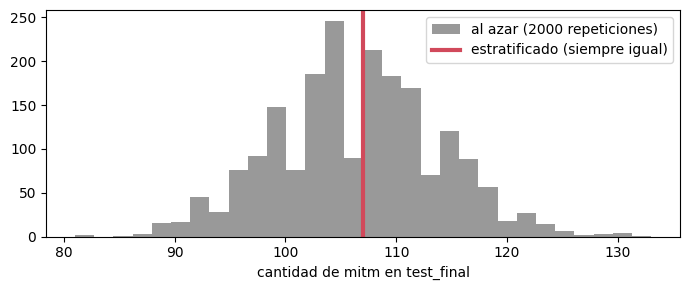

In [17]:
if HAY_REAL:
    tf_tipos = MAN_REAL["splits"]["test_final"]["attack_types"]; to_tipos = MAN_REAL["splits"]["test_oracle"]["attack_types"]
    conteo = {t: tf_tipos[t] + to_tipos[t] for t in tf_tipos}
    conteo["normal"] = MAN_REAL["splits"]["test_final"]["normal"] + MAN_REAL["splits"]["test_oracle"]["normal"]
else:
    conteo = pd.Series(tipos_te).value_counts().to_dict()
claves = np.concatenate([[t] * n for t, n in conteo.items()])
g = np.random.default_rng(0)
al_azar = [(claves[g.permutation(len(claves))[len(claves) // 2:]] == "mitm").sum() for _ in range(2000)]
estrat = [(claves[ps.stratified_halves(g, claves, 0.5)[1]] == "mitm").sum() for _ in range(200)]
print(f"mitm en todo el test: {conteo['mitm']}")
print(f"partiendo AL AZAR:       test_final recibe entre {min(al_azar)} y {max(al_azar)} mitm")
print(f"partiendo ESTRATIFICADO: test_final recibe entre {min(estrat)} y {max(estrat)} mitm")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(al_azar, bins=30, color="#999", label="al azar (2000 repeticiones)")
ax.axvline(np.mean(estrat), color="#D1495B", lw=3, label="estratificado (siempre igual)")
ax.set_xlabel("cantidad de mitm en test_final"); ax.legend(); plt.tight_layout(); plt.show()

## Paso G (opcional): ajustar la proporción de ataques del test
**El problema:** en el test de TON_IoT cerca del **75 %** son ataques. En una red real los ataques son una fracción
pequeña, y con tanto ataque algunas métricas engañan.

> **Ejemplo:** un "detector" que dice **"todo es ataque"** sin mirar nada acierta 3 de cada 4 veces y tiene una
> precisión de 0,75. Parece bueno, pero es inútil.

**Dos soluciones que dejé en el proyecto:**
1. `split.test_target_prevalence: 0.10`: quito ataques del test hasta que sean el 10 %. En el experimento está en
   `null`, es decir, uso la proporción natural.
2. **MCC ajustado** (`MCC_pi05`, `MCC_pi10`): sin botar datos, recalculo el MCC "como si" hubiera 5 % o 10 % de
   ataques. Funciona porque la tasa de detección (TPR) y la de falsas alarmas (FPR) no dependen de cuántos ataques
   haya.

In [18]:
y_ej = np.array([1] * 76 + [0] * 24)
todo_ataque = np.ones(100, dtype=int)
m = common.supervised_metrics(y_ej, todo_ataque)
print(f"'Todo es ataque' con 76 % de ataques: exactitud {((todo_ataque == y_ej).mean()):.2f}, precisión {m['Precision']:.2f}, MCC {m['MCC']:.2f}")
print("-> el MCC (0) sí delata que el detector es inútil; por eso es la métrica principal.\n")
for p in (0.76, 0.10, 0.05):
    print(f"un detector con TPR 0,90 y FPR 0,05 tendría MCC {common.mcc_from_rates(0.90, 0.05, p):.3f} si hubiera {p:.0%} de ataques")

'Todo es ataque' con 76 % de ataques: exactitud 0.76, precisión 0.76, MCC 0.00
-> el MCC (0) sí delata que el detector es inútil; por eso es la métrica principal.

un detector con TPR 0,90 y FPR 0,05 tendría MCC 0.789 si hubiera 76% de ataques
un detector con TPR 0,90 y FPR 0,05 tendría MCC 0.746 si hubiera 10% de ataques
un detector con TPR 0,90 y FPR 0,05 tendría MCC 0.639 si hubiera 5% de ataques


## Paso H: guardo todo con un **sello** (hash SHA-256)
**Qué:** escribo los archivos (`train`, `val`, `test_oracle`, `test_final`, `edge_sample.csv`, `scaler.json`,
`features.json`) y un `manifest.json` con los tamaños, los tipos de ataque y la **huella SHA-256** de cada bloque.

**Por qué:** la huella funciona como un sello de lacre en un sobre: si alguien cambia aunque sea un byte del
archivo, la huella cambia. `5_evaluate.py` revisa el sello de `test_final` antes de abrirlo y, si no coincide, se
niega a evaluar. Así queda evidencia de que la prueba final no se manipuló.

**`edge_sample.csv`:** 2000 filas de `val` **sin etiqueta** que copio a la Raspberry para medir la velocidad. Las
saco de `val` y no del test para no llevar datos de prueba fuera del PC.

In [19]:
correr(ps)    # ejecuta los 8 pasos de una vez, como lo hace run_all.py
man = common.load_json(common.splits_dir(cfg) / "manifest.json")
print("\nHuellas SHA-256:")
for k, v in man["sha256"].items():
    print(f"  {k:12s} {v[:24]}...")

train del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\train_stratified.parquet
test  del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\test_stratified.parquet

preprocesador: train 6,720 filas (normal 4,793, ataque 1,927) | test 1,680 filas (normal 1,207, ataque 473) | 50 columnas numericas
caracteristicas: 40 ({'columnas_entrada': 50, 'constantes': 4, 'binarias_raras': 4, 'numericas_candidatas': 9, 'binarias_candidatas': 37, 'descartadas_por_correlacion': 5, 'conservadas': 40, 'conservadas_numericas': 6, 'conservadas_binarias': 34})



Bloques en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\splits  (formato parquet)
  train       :    4,074 filas
  val         :      719 filas
  test_oracle :      838 filas | ataque 28.0%
  test_final  :      842 filas | ataque 28.3%
+val tiene menos de 1000 filas: umbral y metricas ruidosos. Considere input.variant: processed.

Huellas SHA-256:
  train        e38dae47456339fcc70cdcb6...
  val          f67fd8c2ceb1617a6dbe37aa...
  test_oracle  8d045591769daa9042bfe446...
  test_final   f481ef1d7874ec14457cda0e...


## Resumen: quién ve qué

| Bloque | ¿Tiene etiqueta? | Lo usa | Para qué | ¿Por qué así? |
|---|---|---|---|---|
| `train` | no (solo normal) | todos los detectores | aprender qué es normal | el detector debe conocer solo lo normal |
| `val` / calibración | no (solo normal) | todos | fijar el umbral (5 % de falsas alarmas) | filas que el modelo no vio |
| `val` / objetivo | no (solo normal) | la búsqueda no supervisada | puntuar cada configuración | filas distintas a las del umbral |
| `test_oracle` | sí | oráculo y diagnóstico | cota superior | separado de la prueba final |
| `test_final` | sí | solo `5_evaluate.py`, una vez | resultado de la tesis | nadie lo usó antes; sellado con hash |

---
# Parte 4. Cómo elijo cada cosa

## 4.1 El umbral: percentil q = 0,95 de la calibración, fijo
- Calculo los puntajes de la mitad de calibración (solo normal) y el umbral es el valor que deja al 95 % por debajo.
  Resultado esperado: **5 % de falsas alarmas**.
- **¿Por qué fijo y no optimizado?** En una versión anterior del proyecto el umbral era un hiperparámetro más
  (`contamination`). Las métricas no supervisadas encontraron un truco: subir el umbral hasta que casi nada fuera
  anomalía, porque así los grupos quedaban "bien separados". El resultado era un detector que no detectaba nada.
  Con el umbral fijo, la búsqueda solo puede mejorar el detector, no hacer trampa con la regla.
- Los q 0,90 y 0,99 **solo los reporto** (análisis de sensibilidad); nunca los uso para elegir.

El gráfico muestra los puntajes de un Isolation Forest: verde = normales, rojo = ataques, línea = umbral.

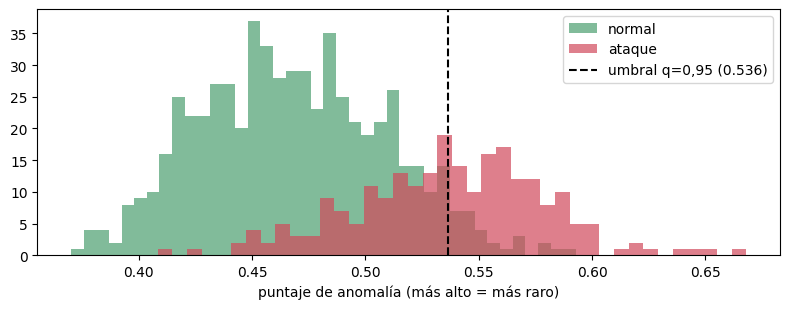

a la derecha de la línea = 'ataque'. Falsas alarmas: 4.8% | ataques detectados: 53.6%


In [20]:
X_o, y_o, _ = common.load_labeled(cfg, "test_oracle")
X_v, _ = common.load_split(cfg, "val"); X_t, _ = common.load_split(cfg, "train")
cal, obj = common.split_val(X_v, cfg)
det = detectors.IForestDetector(n_estimators=100, random_state=0).fit(X_t).set_threshold(cal, q=0.95)
s = det.scores(X_o)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(s[y_o == 0], bins=40, alpha=.7, color="#4C9F70", label="normal")
ax.hist(s[y_o == 1], bins=40, alpha=.7, color="#D1495B", label="ataque")
ax.axvline(det.threshold_, color="k", ls="--", label=f"umbral q=0,95 ({det.threshold_:.3f})")
ax.set_xlabel("puntaje de anomalía (más alto = más raro)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"a la derecha de la línea = 'ataque'. Falsas alarmas: {(s[y_o == 0] > det.threshold_).mean():.1%} | ataques detectados: {(s[y_o == 1] > det.threshold_).mean():.1%}")

## 4.2 Los hiperparámetros: Optuna (TPE), guiado por una métrica sin etiquetas
1. **Pruebo una configuración** (un *trial*): Optuna propone valores para las perillas (por ejemplo 200 árboles,
   512 filas por árbol).
2. **La entreno** con `train` y fijo el umbral con la calibración.
3. **Reviso si cabe en la Raspberry**: si tarda más de 20 ms por flujo en el PC (supongo que la Pi es unas 5 veces
   más lenta: 100 ms ÷ 5) o pesa más de 50 MB, la descarto.
4. **Le pongo nota** con la métrica no supervisada en la mitad *objetivo* (por ejemplo, Silhouette).
5. **Optuna aprende de las notas** y propone la siguiente configuración cerca de las que funcionaron bien (eso es
   TPE). Repito esto 100 veces, con 5 semillas distintas.
6. Guardo las **5 mejores** (top-5), no solo la mejor (ver 4.4).

**¿Qué métrica uso con cada detector?** (Tabla 3.6 de la memoria)

| Detector | Métricas | Idea de la métrica |
|---|---|---|
| Isolation Forest | Silhouette, Davies–Bouldin | ¿separa con claridad los puntajes "altos" de los "bajos"? |
| LOF | Silhouette, Davies–Bouldin | ídem |
| Autoencoder | Error de reconstrucción, Estabilidad | ¿copia bien lo normal? ¿su ranking resiste un poco de ruido? |

Ejemplo de una búsqueda corta (6 intentos) para ver cómo se ve cada *trial*:

In [21]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
filas = []
def objetivo(trial):
    p = search_space.suggest_params(trial, "iforest", 42, cfg)
    d = detectors.IForestDetector(**p).fit(X_t).set_threshold(cal, 0.95)
    nota = objectives.compute_objective("silhouette", d, obj, cfg)
    filas.append({"trial": trial.number, "n_estimators": p["n_estimators"], "max_samples": p["max_samples"],
                  "max_features": round(p["max_features"], 2), "silhouette": round(nota, 4)})
    return nota
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo, n_trials=6)
pd.DataFrame(filas).sort_values("silhouette", ascending=False)

,trial,n_estimators,max_samples,max_features,silhouette
4,4,100,2038,0.43,0.5264
3,3,50,1214,0.98,0.5136
5,5,125,136,0.67,0.5078
0,0,300,302,0.81,0.4983
2,2,275,81,0.72,0.4915
1,1,75,769,0.41,0.4868


## 4.3 Los tres escenarios que comparo
| Escenario | Cómo se eligen las perillas | ¿Usa etiquetas? | ¿Para qué sirve? |
|---|---|---|---|
| **Línea base** | valores por defecto de la biblioteca | no | punto de partida: ¿la búsqueda mejora algo? |
| **Optimizada** | la búsqueda con una métrica no supervisada | no | **mi propuesta** |
| **Oráculo** | la búsqueda maximizando el MCC en `test_oracle` | sí | techo: lo máximo alcanzable |

Si "optimizada" queda cerca del oráculo, la métrica no supervisada es una buena guía.

## 4.4 El modelo final: el primero del top-5 que cumple en la Raspberry
- La búsqueda deja 5 candidatos ordenados por **su propia métrica** (el rango 0 es el mejor).
- En la Raspberry mido cada uno (latencia, CPU y RAM) y elijo **el primero de la lista que cumple los tres
  límites**: latencia p95 < 100 ms, CPU < 50 % recibiendo 100 flujos por segundo y RAM < 512 MB.
- **¿Por qué no elijo el de mejor MCC en el test?** Porque eso sería usar la respuesta de la prueba para elegir
  (fuga). El MCC solo lo reporto al final.

## 4.5 Cuándo digo que la optimización **mejora** la línea base: solo si la diferencia supera el ruido
Repito todo con **5 semillas** (5 repeticiones con distinto azar). Para cada semilla calculo
Δ = MCC optimizado − MCC base. Digo que **mejora** solo si el promedio de Δ es mayor que **2 errores estándar**
(una medida de cuánto "baila" el resultado entre repeticiones); que **empeora** si es menor que −2 errores
estándar; y si no, que la **mantiene**.

In [22]:
deltas = np.array([0.04, 0.06, 0.03, 0.05, 0.07])          # ejemplo: delta de MCC en 5 semillas
ee = deltas.std(ddof=1) / np.sqrt(len(deltas))
print(f"delta medio = {deltas.mean():.3f} | error estándar = {ee:.4f} | 2 EE = {2 * ee:.4f}")
print("¿mejora?", "SÍ" if deltas.mean() - 2 * ee > 0 else "no se puede afirmar")
ruidoso = np.array([0.10, -0.08, 0.05, -0.06, 0.04])
ee2 = ruidoso.std(ddof=1) / np.sqrt(5)
print(f"\notro ejemplo, muy variable: delta medio = {ruidoso.mean():.3f}, 2 EE = {2 * ee2:.3f} ->",
      "SÍ" if ruidoso.mean() - 2 * ee2 > 0 else "no se puede afirmar (mantiene)")

delta medio = 0.050 | error estándar = 0.0071 | 2 EE = 0.0141
¿mejora? SÍ

otro ejemplo, muy variable: delta medio = 0.010, 2 EE = 0.069 -> no se puede afirmar (mantiene)


---
# Referencia: cada función, una por una

Desde aquí recorro **todas las funciones** de cada archivo, en orden de ejecución. Las partes anteriores explican
el porqué; esta sección es el detalle de cada función.

---
# A. `run_all.py`: el orquestador

Es el único archivo que hay que ejecutar en el día a día. Corre las etapas en orden, cada una en su propio proceso,
y se detiene si alguna falla.

```
python run_all.py --config config/experiment_v2.yaml   # todo el experimento (versión 2)
python run_all.py --rapido                              # prueba corta de todo
python run_all.py --etapas splits,optimizar             # solo algunas etapas
python run_all.py --etapas borde                        # en la Raspberry
```

Constantes:
- `ROOT`, `SRC`, `PRE_V2`: carpetas del proyecto, de `src/` y del preprocesador.
- `CSV_REL`: carpeta donde debe estar `Train_Test_Network.csv`.
- `ALL`: todas las etapas en orden; `DEFAULT`: las que corre si no se indica nada (sin `diagnostico`, que es
  opcional, ni `borde`, que se corre en la Raspberry).

In [23]:
import run_all
print("Todas las etapas:", run_all.ALL)
print("Por defecto:     ", run_all.DEFAULT)

Todas las etapas: ['preprocesar', 'splits', 'diagnostico', 'optimizar', 'borde', 'evaluar', 'reporte']
Por defecto:      ['preprocesar', 'splits', 'optimizar', 'evaluar', 'reporte']


### `run(cmd, cwd, env_extra=None)`
**Para qué sirve:** ejecutar un comando (un script de Python) y detener todo si falla.

**Cómo lo hace:** copia las variables de entorno y les agrega `env_extra`, muestra el comando,
lo ejecuta con `subprocess.run` y mide cuánto demoró. Si el código de salida no es 0, termina el
programa con `sys.exit` y el mensaje de fallo, para no seguir con datos incompletos.

In [24]:
# Lo que imprime el subproceso sale en la terminal de Jupyter; aqui se ve el comando y el tiempo.
run_all.run([sys.executable, "-c", "print('hola desde un subproceso')"], RAIZ)


$ C:\Users\belen\Desktop\tesis_hpo_edge\.venv\Scripts\python.exe -c print('hola desde un subproceso')


   ok en 0.1s


### `etapa_preprocesar(cfg)`
**Para qué sirve:** correr los pasos del preprocesador (CSV de TON_IoT → Parquet) para el dataset de la
configuración (`Ton-IoT` en la v1, `Ton-IoT-v2` en la v2).

**Cómo lo hace:**
1. Revisa que exista `preprocessor/preprocessor_v2/`.
2. Ejecuta `scripts/0_configurar_preprocessor.py` para que el preprocesador apunte a esta carpeta.
3. **Protege el CSV original:** el paso 00 lee `Train_Test_Labels.csv`. Si falta, copia
   `Train_Test_Network.csv` → `Train_Test_Labels.csv`. (En la versión original, si no lo encontraba, el paso 00
   leía su propio archivo de salida; lo corregí en la v2, pero mantengo la copia.)
4. Define `PYTHONUTF8=1` y `PYTHONIOENCODING=utf-8`, porque el código del preprocesador imprime emojis y lee
   `config.yaml` sin indicar la codificación (en Windows eso falla).
5. Ejecuta `00_source_preprocessing/run.py`, `01_train_test_split.py` y `02_preprocessing.py`. El paso
   `03_stratified_subset.py` solo lo corre si `input.variant: stratified`, y `04_feature_selection.py` solo si
   `features.mode: selector`.

*(No lo ejecuto aquí porque procesa el dataset real.)*

### `main()`
**Para qué sirve:** leer las opciones de la terminal y correr las etapas pedidas.

**Cómo lo hace:** con `argparse` lee `--etapas`, `--config`, `--rapido` y `--saltar-preprocessor`;
revisa que las etapas existan; lee `features.mode` de la configuración y, para cada etapa, llama a
`run(...)` con el script numerado que corresponde (`1_prepare_splits.py`, `3_optimize.py`, ...).
Con `--rapido`, la optimización se corre con `--fast` (25 trials, 1 semilla).

---
# B. `scripts/` — preparar el entorno (paso 0)

## `scripts/0_check_env.py`
Revisa que estén instaladas las librerías necesarias. Las listas `REQ_PC` y `REQ_PI` son las
obligatorias en el PC y en la Raspberry; `REQ_PRE` (lightgbm, statsmodels) solo hace falta con
`features.mode: selector`; `OPCIONAL` (tensorflow) solo para entrenar el autoencoder con Keras.

### `ver(mod)`
**Para qué sirve:** saber si una librería está instalada y qué versión tiene.
**Cómo lo hace:** intenta importarla con `importlib.import_module`; si lo logra devuelve
`__version__`, y si falla devuelve `None`.

### `main()`
**Para qué sirve:** mostrar la tabla de librerías (OK / FALTA) según el rol (`--rol pc` o `--rol pi`).
**Cómo lo hace:** recorre la lista obligatoria del rol con `ver`; en el PC muestra también las
opcionales. Devuelve 1 (error) si falta alguna obligatoria, para que un script que lo llame lo note.

In [25]:
check_env = importlib.import_module("0_check_env")
print("numpy:", check_env.ver("numpy"), "| tensorflow:", check_env.ver("tensorflow"))
correr(check_env, con_config=False)

numpy: 2.2.6 | tensorflow: None
Python 3.10.11 | Windows-10-10.0.26200-SP0
  OK  numpy        2.2.6
  OK  pandas       2.3.3
  OK  scipy        1.15.3
  OK  sklearn      1.7.2
  OK  yaml         6.0.3
  OK  psutil       7.2.2
  OK  optuna       5.0.0
  OK  pyarrow      25.0.1
  --  lightgbm     (opcional)
  --  statsmodels  (opcional)
  --  tensorflow   (opcional)

Todo listo.


## `scripts/0_configurar_preprocessor.py`
Ajusta **solo los archivos de configuración** del preprocesador (`config.yaml` y `config.json`),
nunca sus `.py`, para que funcione dentro de esta carpeta.

### `backup(p)`
**Para qué sirve:** guardar una copia del archivo original antes de cambiarlo.
**Cómo lo hace:** copia `archivo` → `archivo.bak_proyecto`, **solo si la copia todavía no existe**
(así la copia siempre es el archivo original, aunque el script se corra muchas veces).

### `yaml_quote(s)`
**Para qué sirve:** escribir una ruta en el YAML de forma que se lea bien aunque tenga tildes.
**Cómo lo hace:** pone el texto entre comillas, escapa `"` y `\`, y convierte cada carácter
no ASCII a `\uXXXX`. El YAML entre comillas dobles interpreta esos códigos, así que no importa
con qué codificación abra el archivo Windows.

In [26]:
cp = importlib.import_module("0_configurar_preprocessor")
print(cp.yaml_quote("C:/Users/belén/Desktop/tesis"))

"C:/Users/bel\u00e9n/Desktop/tesis"


### `patch_yaml(text, root_posix)`
**Para qué sirve:** cambiar `ROOT` y `RESULTS` del entorno `high_performance` de `config.yaml`
para que apunten a esta carpeta.

**Cómo lo hace:** busca la línea `  high_performance:` y el final de ese bloque (la siguiente línea
con 2 espacios de sangría). Dentro del bloque reemplaza las líneas `    ROOT:` y `    RESULTS:`,
**conservando el salto de línea original** (`\r\n` o `\n`). Devuelve el texto nuevo y si hubo cambios.
No usa `yaml.dump` a propósito: así no se pierden los comentarios ni el orden del archivo original.

In [27]:
ejemplo_yaml = '''environments:
  google_colab:
    ROOT: /content/drive
  high_performance:
    RESULTS: "C:/viejo/RESULTS"
    ROOT: "C:/viejo"
    CHUNKSIZE: 500000
'''
nuevo, cambio = cp.patch_yaml(ejemplo_yaml, "C:/Users/belen/Desktop/tesis_hpo_edge")
print(nuevo, "\ncambio:", cambio)

environments:
  google_colab:
    ROOT: /content/drive
  high_performance:
    RESULTS: "C:/Users/belen/Desktop/tesis_hpo_edge/RESULTS"
    ROOT: "C:/Users/belen/Desktop/tesis_hpo_edge"
    CHUNKSIZE: 500000
 
cambio: True


### `patch_json(jtext)`
**Para qué sirve:** quitar la `/` inicial de la ruta `"path"` de Ton-IoT en `config.json`.
Con esa barra, en Windows la ruta se toma como absoluta (`C:\Datasets\...`) y se ignora `ROOT`.

**Cómo lo hace:** con expresiones regulares encuentra el bloque `"Ton-IoT": {`, delimita dónde
termina (donde empieza el siguiente dataset) y, dentro, la clave `"path"`. Reemplaza **solo** ese
valor y deja el resto del texto idéntico. Devuelve `(texto, ruta_final, hubo_cambio)`.

In [28]:
ejemplo_json = '''{
    "Ton-IoT": {
        "path": "/Datasets/Sources/TON-IoT/preprocessed.csv",
        "label": "category"
    },
    "Otro": {
        "path": "/no/se/toca.csv"
    }
}'''
texto, ruta, cambio = cp.patch_json(ejemplo_json)
print(texto, "\nruta:", ruta, "| cambio:", cambio)

{
    "Ton-IoT": {
        "path": "Datasets/Sources/TON-IoT/preprocessed.csv",
        "label": "category"
    },
    "Otro": {
        "path": "/no/se/toca.csv"
    }
} 
ruta: Datasets/Sources/TON-IoT/preprocessed.csv | cambio: True


### `main()`
**Para qué sirve:** aplicar los dos cambios anteriores a los archivos reales del preprocesador.
**Cómo lo hace:** (1) revisa que exista el preprocesador; (2) lee `config.yaml` con `newline=""`
(para no alterar los saltos de línea), aplica `patch_yaml`, hace `backup` y escribe; (3) lo mismo con
`config.json` y `patch_json`; (4) avisa si el CSV de TON_IoT ya está en su carpeta.
*(No se ejecuta aquí: modifica la configuración real del preprocessor.)*

---
# C. `common.py` — utilidades que usan todas las etapas

## Configuración

### `deep_merge(base, over)`
**Para qué sirve:** combinar dos configuraciones; los valores de `over` mandan.
**Cómo lo hace:** copia `base` y recorre `over`; si ambos valores son diccionarios se mezclan
**por dentro** (recursivamente) en vez de reemplazar el diccionario entero. Así un YAML de prueba
puede cambiar solo `optimization.n_trials` sin borrar el resto de `optimization`.

In [29]:
base = {"optimization": {"n_trials": 100, "seeds": [42, 43]}, "edge": {"max_ram_mb": 512}}
over = {"optimization": {"n_trials": 5}}
common.deep_merge(base, over)

{'optimization': {'n_trials': 5, 'seeds': [42, 43]},
 'edge': {'max_ram_mb': 512}}

### `load_config(path=None)`
**Para qué sirve:** leer la configuración del experimento. Es la **única fuente** de parámetros.
**Cómo lo hace:** lee `config/experiment.yaml`; si se entrega otro YAML en `path`, lo mezcla encima
con `deep_merge`. Guarda en `_config_path` qué archivo se usó.

In [30]:
print("n_trials (prueba):", cfg["optimization"]["n_trials"], "| q:", cfg["threshold"]["q"],
      "| max_features:", cfg["features"]["max_features"])

n_trials (prueba): 5 | q: 0.95 | max_features: 40


### `_resolve(p)` y las funciones de carpetas
`_resolve` convierte una ruta en absoluta: si es relativa, la toma desde la raíz del proyecto
(y expande `~`). Así el proyecto funciona sin importar desde qué carpeta se ejecute.

`datasets_dir`, `splits_dir`, `outputs_dir`, `models_dir` y `results_dir` devuelven las carpetas
según `cfg["paths"]`. Están centralizadas para que ningún script escriba rutas a mano.

In [31]:
for f in (common.datasets_dir, common.splits_dir, common.outputs_dir, common.models_dir, common.results_dir):
    print(f"{f.__name__:13s} ->", f(cfg))
print("_resolve('config') ->", common._resolve("config"))

datasets_dir  -> C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets
splits_dir    -> C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\splits
outputs_dir   -> C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs
models_dir    -> C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\models
results_dir   -> C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\results
_resolve('config') -> C:\Users\belen\Desktop\tesis_hpo_edge\config


## Entrada / salida

### `parquet_available()` e `io_ext()`
**Para qué sirven:** decidir el formato en que se guardan los bloques.
**Cómo lo hacen:** `parquet_available` intenta importar `pyarrow` o `fastparquet`; `io_ext`
devuelve `"parquet"` si hay alguna y `"csv"` si no (por ejemplo, en una Raspberry sin pyarrow).

### `find_table(base)`
**Para qué sirve:** encontrar una tabla sin saber su extensión.
**Cómo lo hace:** prueba `base.parquet` y luego `base.csv`; si no existe ninguno lanza `FileNotFoundError`.

### `read_table(path)` y `write_table(df, path)`
**Para qué sirven:** leer y guardar tablas en parquet o csv según la extensión.
**Cómo lo hacen:** miran `path.suffix`; `write_table` además crea la carpeta si falta.

In [32]:
print("formato:", common.io_ext())
df_demo = pd.DataFrame({"a": [1, 2, 3], "b": [0.1, 0.2, 0.3]})
common.write_table(df_demo, TMP / "demo" / f"tabla.{common.io_ext()}")
ruta = common.find_table(TMP / "demo" / "tabla")
print("encontrada:", ruta.name)
common.read_table(ruta)

formato: parquet
encontrada: tabla.parquet


,a,b
0,1,0.1
1,2,0.2
2,3,0.3


### `sha256_of(path)`
**Para qué sirve:** obtener una "huella digital" de un archivo para detectar si cambió. Así
`5_evaluate.py` comprueba que `test_final` es exactamente el mismo que se creó en el paso 1.
**Cómo lo hace:** lee el archivo en bloques de 1 MB (no lo carga entero a memoria) y actualiza
un hash SHA-256. Un solo byte distinto produce una huella completamente distinta.

In [33]:
p = TMP / "demo" / "texto.txt"
p.write_text("hola")
h1 = common.sha256_of(p)
p.write_text("hola!")
print(h1[:16], "...\n" + common.sha256_of(p)[:16], "...  <- cambió con un solo carácter")

b221d9dbb083a7f3 ...
a80897215bfeca30 ...  <- cambió con un solo carácter


### `save_json(obj, path)` y `load_json(path)`
Guardan y leen JSON en UTF-8. `save_json` crea la carpeta, usa sangría (legible) y
`default=str` para que tipos como `Path` no provoquen error.

### `set_seeds(seed)`
**Para qué sirve:** que los resultados se puedan repetir.
**Cómo lo hace:** fija la semilla de `random` y de `numpy.random` (el generador global).

In [34]:
common.save_json({"ruta": TMP, "valores": [1, 2]}, TMP / "demo" / "x.json")
print(common.load_json(TMP / "demo" / "x.json"))
common.set_seeds(0); a = np.random.rand(3)
common.set_seeds(0); b = np.random.rand(3)
print("misma semilla -> mismos números:", np.allclose(a, b))

{'ruta': 'C:\\Users\\belen\\AppData\\Local\\Temp\\cuaderno_lrgwvn4i', 'valores': [1, 2]}


misma semilla -> mismos números: True


## Particiones (se ejecutan en la parte D, cuando ya existen los bloques)

- `NON_FEATURE = ("y_true", "attack_type")`: columnas que **no** son variables de entrada.
- **`split_path(cfg, name)`**: ruta del archivo de un bloque (`train`, `val`, `test_oracle`, `test_final`).
- **`load_labeled(cfg, name)`**: lee un bloque y devuelve `(X, y, tipos)`. Si el bloque no tiene la
  columna `y_true` (train y val), `y` y `tipos` son `None`. `X` queda en `float32` sin las columnas de
  `NON_FEATURE`.
- **`load_split(cfg, name)`**: igual, pero devuelve solo `(X, y)`.
- **`split_val(X_val, cfg)`**: parte `val` en dos mitades sin filas en común, siempre iguales
  (semilla `split.seed`): **calibración** (para fijar el umbral) y **objetivo** (para calcular la
  métrica). Así el umbral y la métrica no se calculan con las mismas filas.
- **`subsample(X, max_rows, seed=42)`**: toma `max_rows` filas al azar sin repetir (o todas si hay menos).
- **`train_for(cfg, detector, X_train)`**: filas de entrenamiento de cada detector. Aplica
  `max_train_rows` y, para LOF, además `max_train_rows_lof` (LOF guarda todo el train en memoria).
  Ojo: como el tope de LOF se aplica después del general, no tiene efecto si es mayor.

In [35]:
X = np.arange(20).reshape(10, 2)
print("subsample a 3 filas:\n", common.subsample(X, 3))
print("sin tope -> mismas filas:", common.subsample(X, None).shape)

subsample a 3 filas:
 [[18 19]
 [ 0  1]
 [12 13]]
sin tope -> mismas filas: (10, 2)


## Métricas supervisadas
Solo las usan el **oráculo** (con `test_oracle`), `2_diagnose.py` y `5_evaluate.py` (con `test_final`).

### `mcc_from_rates(tpr, fpr, prevalence)`
**Para qué sirve:** calcular el MCC que se obtendría si la proporción de ataques fuera
`prevalence`. TON_IoT tiene ~76 % de ataques, algo irreal en una red; con esto se reporta el MCC
"como si hubiera 5 % o 10 % de ataques" sin botar datos.
**Cómo lo hace:** TPR y FPR no dependen de cuántos ataques haya. Con ellos y la prevalencia `p`
rearma la matriz de confusión en proporciones (`tp = p·TPR`, `fn = p·(1-TPR)`,
`fp = (1-p)·FPR`, `tn = (1-p)·(1-FPR)`) y aplica la fórmula del MCC. Si el denominador es 0 devuelve 0.

In [36]:
for p in (0.76, 0.10, 0.05):
    print(f"TPR=0.90, FPR=0.05, prevalencia {p:.0%} -> MCC = {common.mcc_from_rates(0.90, 0.05, p):.3f}")

TPR=0.90, FPR=0.05, prevalencia 76% -> MCC = 0.789
TPR=0.90, FPR=0.05, prevalencia 10% -> MCC = 0.746
TPR=0.90, FPR=0.05, prevalencia 5% -> MCC = 0.639


### `supervised_metrics(y_true, y_pred, prevalences=())`
**Para qué sirve:** todas las métricas que comparan lo predicho con la etiqueta real.
**Cómo lo hace:** arma la matriz de confusión (`tn, fp, fn, tp`) y calcula MCC, BACC, F1, Recall,
Precision, FPR y FNR (con `zero_division=0` para no fallar con clases vacías), más los conteos. Por
cada prevalencia agrega `MCC_piXX` usando `mcc_from_rates`.

### `ranking_metrics(y_true, scores)`
**Para qué sirve:** métricas que **no dependen del umbral**: AUROC y AUPRC.
**Cómo lo hace:** usa los puntajes continuos. Si `y_true` tiene una sola clase devuelve `NaN`
(no se pueden calcular).

In [37]:
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 0])
y_pred = np.array([0, 0, 1, 0, 1, 1, 0, 0])
puntajes = np.array([.1, .2, .7, .3, .9, .8, .4, .2])
print(common.supervised_metrics(y_true, y_pred, prevalences=(0.05, 0.10)))
print(common.ranking_metrics(y_true, puntajes))

{'MCC': 0.4666666666666667, 'BACC': 0.7333333333333334, 'F1': 0.6666666666666666, 'Recall': 0.6666666666666666, 'Precision': 0.6666666666666666, 'FPR': 0.2, 'FNR': 0.33333333333333337, 'TP': 2, 'TN': 4, 'FP': 1, 'FN': 1, 'MCC_pi05': 0.24420777043715688, 'MCC_pi10': 0.32477247200848736}
{'AUROC': 0.9333333333333333, 'AUPRC': 0.9166666666666665}


---
# D. `1_prepare_splits.py`: los bloques de datos (paso 1)

Toma lo que deja el preprocesador (`train_*` y `test_*`, ambos con tráfico normal y ataques) y arma:

| Bloque | Contenido | Quién lo usa |
|---|---|---|
| `train` | solo normal, **sin etiquetas** (85 % del normal del train del preprocesador) | entrenar |
| `val` | solo normal, **sin etiquetas** (15 %) | calibrar el umbral y calcular la métrica |
| `test_oracle` | normal y ataques, con etiquetas (50 % del test) | solo el oráculo y el diagnóstico |
| `test_final` | normal y ataques, con etiquetas (50 % del test) | solo `5_evaluate.py`, una vez |

`HINT` es un diccionario que dice qué paso del preprocesador falta, según el archivo que no se encuentre.

In [38]:
ps = importlib.import_module("1_prepare_splits")

### `input_bases(cfg)`
**Para qué sirve:** decidir qué archivos del preprocesador leer.
**Cómo lo hace:** con `features.mode: selector` usa `Parquet/<dataset>/<selector>/{train,test}/best_features`
(salida del paso 04); si no, `train_<variant>` y `test_<variant>` con `variant` = `stratified` (10 %)
o `processed` (100 %). Devuelve las rutas **sin extensión** (las completa `find_table`).

### `read_inputs(cfg)`
**Para qué sirve:** leer el train y el test del preprocessor.
**Cómo lo hace:** busca los archivos con `find_table`; si faltan, termina con un mensaje que dice
**qué paso del preprocesador** hay que correr (usando `HINT`).

In [39]:
print(ps.input_bases(cfg))
df_tr, df_te = ps.read_inputs(cfg)
df_tr.head(3)

(WindowsPath('C:/Users/belen/AppData/Local/Temp/cuaderno_lrgwvn4i/Datasets/Parquet/Ton-IoT/train_stratified'), WindowsPath('C:/Users/belen/AppData/Local/Temp/cuaderno_lrgwvn4i/Datasets/Parquet/Ton-IoT/test_stratified'), 'stratified')
train del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\train_stratified.parquet
test  del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\test_stratified.parquet


,duration,src_bytes,dst_bytes,src_pkts,dst_pkts,missed_bytes,src_ip_bytes,dst_ip_bytes,http_request_body_len,http_response_body_len,...,cat_26,cat_27,cat_28,cat_29,const_col,rare_col,dup_src_bytes,type,category,label
0,0.108494,0.015792,0.012134,0.009653,0.242424,0.0,0.017490,0.013916,0.0,0.0,...,0,1,1,0,0,0,0.015792,normal,0,0
1,0.037221,0.040656,0.004689,0.011583,0.181818,0.0,0.042538,0.006044,0.0,0.0,...,0,0,0,0,0,0,0.040656,normal,0,0
2,0.127218,0.004895,0.031043,0.009653,0.212121,0.0,0.006672,0.032513,0.0,0.0,...,1,1,0,0,0,0,0.004895,normal,0,0


### `build_target(df, cfg)`
**Para qué sirve:** crear la etiqueta binaria **1 = ataque, 0 = normal**.
**Cómo lo hace:** toma la columna `dataset.label_col` (`category`) y marca 1 todo lo que sea distinto de
`dataset.normal_value` (0). Si la columna es numérica compara como número; si no, como texto
(sin espacios y en minúsculas), así funciona tanto con `0` como con `"normal"`.

### `attack_types(df, cfg, y)`
**Para qué sirve:** el tipo de ataque de cada fila (para el recall por tipo y para estratificar).
**Cómo lo hace:** lee `dataset.attack_type_col` (`type`); en las filas normales escribe `"normal"`.

### `feature_frame(df, cfg)`
**Para qué sirve:** dejar solo las variables de entrada.
**Cómo lo hace:** quita las columnas de etiqueta y tipo (`drop_cols`), se queda con las numéricas y
booleanas, las pasa a `float32` y reemplaza infinitos y vacíos por 0.

In [40]:
y_tr, y_te = ps.build_target(df_tr, cfg), ps.build_target(df_te, cfg)
tipos_te = ps.attack_types(df_te, cfg, y_te)
X_tr_all = ps.feature_frame(df_tr, cfg)
print("train: normal", (y_tr == 0).sum(), "| ataque", (y_tr == 1).sum())
print("tipos en test:", pd.Series(tipos_te).value_counts().to_dict())
print("variables:", X_tr_all.shape[1])

train: normal 4793 | ataque 1927
tipos en test: {'normal': 1207, 'ddos': 168, 'scanning': 118, 'password': 75, 'injection': 45, 'xss': 45, 'mitm': 22}
variables: 50


### `binary_mask(A, chunk=256)`
**Para qué sirve:** saber qué columnas son 0/1 (las que salen del one-hot).
**Cómo lo hace:** revisa si todos los valores de la columna son 0 o 1. Lo hace por grupos de 256
columnas para no crear una matriz booleana gigante en memoria.

In [41]:
A = np.array([[0, 1, 0.5], [1, 0, 2.0], [1, 1, 0.0]])
ps.binary_mask(A)

array([ True,  True, False])

### `select_unsupervised(Xtr, cfg, seed)`
**Para qué sirve:** reducir las ~290 columnas a como mucho `max_features` (40) **sin mirar etiquetas**,
usando solo el train normal. Menos columnas = modelo más liviano para la Raspberry.

**Cómo lo hace:**
1. **Quita** las columnas constantes y las 0/1 "raras": aquellas cuyo valor menos común aparece en
   menos del `min_minority_freq` (0,1 %) del tráfico normal.
2. **Ordena** las que quedan: primero las numéricas y después las 0/1, de más a menos variables
   según `p(1−p)` (una columna 0/1 con p = 0,5 tiene la máxima variabilidad).
3. **Filtro de correlación:** calcula la matriz de correlación con una muestra de hasta 20 000 filas
   y recorre las columnas en ese orden; descarta una columna si su |r| con alguna ya elegida es
   ≥ `max_abs_corr` (0,95). Se detiene al llegar a `max_features`.

Devuelve la lista de columnas y un diccionario con cuántas se descartaron en cada filtro.
En los datos sintéticos hay tres columnas "trampa": `const_col` (constante), `rare_col` (casi siempre 0)
y `dup_src_bytes` (casi idéntica a `src_bytes`). Las tres deben desaparecer.

In [42]:
normal_tr = X_tr_all[y_tr == 0].reset_index(drop=True)
feats, stats = ps.select_unsupervised(normal_tr, cfg, seed=42)
print(stats)
print("¿sobrevivió alguna trampa?", [c for c in ("const_col", "rare_col", "dup_src_bytes") if c in feats])

{'columnas_entrada': 50, 'constantes': 4, 'binarias_raras': 4, 'numericas_candidatas': 9, 'binarias_candidatas': 37, 'descartadas_por_correlacion': 5, 'conservadas': 40, 'conservadas_numericas': 6, 'conservadas_binarias': 34}
¿sobrevivió alguna trampa? []


### `fit_scaler(Xtr, cfg)` y `apply_scaler(X, sc)`
**Para qué sirven:** estandarizar las variables con estadísticos **del train normal**.
**Cómo lo hacen:** `fit_scaler` calcula media y desviación de cada columna (si la desviación es ~0
usa 1 para no dividir por 0). En las columnas 0/1 fija media 0 y desviación 1, así **quedan iguales**.
Con `scaling.method: none` no escala nada. Devuelve un diccionario (se guarda como `scaler.json`).
`apply_scaler` calcula `(x − media) / desviación` y recorta a `[−clip, clip]` (10) para que unos
pocos valores extremos no desestabilicen al autoencoder ni a LOF.

In [43]:
sc = ps.fit_scaler(normal_tr[feats], cfg)
Z = ps.apply_scaler(normal_tr[feats], sc)
print("media de las numéricas tras escalar:", Z[feats[:3]].mean().round(3).to_dict())
print("una columna 0/1 queda igual:", feats[-1], sorted(Z[feats[-1]].unique()))

media de las numéricas tras escalar: {'duration': -0.0010000000474974513, 'src_bytes': -0.004000000189989805, 'dst_bytes': -0.00800000037997961}
una columna 0/1 queda igual: cat_16 [np.float32(0.0), np.float32(1.0)]


### `stratified_halves(rng, keys, frac_first)`
**Para qué sirve:** partir el test en `test_oracle` y `test_final` **manteniendo la proporción de cada
grupo** (normal y cada tipo de ataque).
**Cómo lo hace:** para cada grupo, mezcla sus índices y pone `floor(frac_first · n)` en la primera
parte y el resto en la segunda. Si un grupo tiene una sola fila, va a la segunda (la de evaluación).

In [44]:
claves = np.array(["normal"] * 6 + ["ddos"] * 4 + ["mitm"] * 1)
a, b = ps.stratified_halves(np.random.default_rng(0), claves, 0.5)
print("primera:", pd.Series(claves[a]).value_counts().to_dict())
print("segunda:", pd.Series(claves[b]).value_counts().to_dict())

primera: {'normal': 3, 'ddos': 2}
segunda: {'normal': 3, 'ddos': 2, 'mitm': 1}


### `main()`
**Para qué sirve:** ejecutar todo el paso 1 y escribir los bloques.
**Cómo lo hace:**
1. Lee los datos, crea etiquetas, tipos y variables.
2. **train / val:** mezcla los índices del tráfico **normal** del train del preprocesador y separa
   el `val_frac_of_normal` (15 %) para `val`. Los ataques de ese train se descartan.
3. **Variables y escalado:** elige columnas y ajusta el escalador **solo con train**, y aplica lo
   mismo a val y test (las columnas que falten en test se rellenan con 0).
4. **Test:** opcionalmente quita ataques hasta llegar a `test_target_prevalence`; luego lo parte con
   `stratified_halves` en `test_oracle` y `test_final`.
5. Escribe los bloques (solo los de prueba llevan `y_true` y `attack_type`), `edge_sample.csv`
   (filas de val **sin etiquetas** para la Raspberry), `scaler.json`, `features.json` y
   `manifest.json` (tamaños, tipos de ataque y **hash SHA-256** de cada bloque).
6. Avisa si la prevalencia del test es >50 %, si hay pocos normales en `test_oracle` o si `val` es chico.

La función interna `block(idx)` resume un bloque de prueba (filas, normales, ataques, proporción y
cantidad por tipo) para el manifiesto.

In [45]:
correr(ps)
manifiesto = common.load_json(common.splits_dir(cfg) / "manifest.json")
pd.DataFrame(manifiesto["splits"]).T[["rows", "normal", "attack", "attack_ratio"]]

train del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\train_stratified.parquet
test  del preprocesador: C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\Datasets\Parquet\Ton-IoT\test_stratified.parquet



preprocesador: train 6,720 filas (normal 4,793, ataque 1,927) | test 1,680 filas (normal 1,207, ataque 473) | 50 columnas numericas
caracteristicas: 40 ({'columnas_entrada': 50, 'constantes': 4, 'binarias_raras': 4, 'numericas_candidatas': 9, 'binarias_candidatas': 37, 'descartadas_por_correlacion': 5, 'conservadas': 40, 'conservadas_numericas': 6, 'conservadas_binarias': 34})



Bloques en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\splits  (formato parquet)
  train       :    4,074 filas
  val         :      719 filas
  test_oracle :      838 filas | ataque 28.0%
  test_final  :      842 filas | ataque 28.3%
+val tiene menos de 1000 filas: umbral y metricas ruidosos. Considere input.variant: processed.


,rows,normal,attack,attack_ratio
train,4074,NaN,NaN,NaN
val,719,NaN,NaN,NaN
test_oracle,838,603,235,0.2804
test_final,842,604,238,0.2827


### Las funciones de `common.py` que leen bloques, ya con datos

In [46]:
X_train, _ = common.load_split(cfg, "train")
X_val, y_val = common.load_split(cfg, "val")
X_orc, y_orc, tipos_orc = common.load_labeled(cfg, "test_oracle")
X_cal, X_obj = common.split_val(X_val, cfg)
print("train", X_train.shape, "| val", X_val.shape, "-> y de val:", y_val)
print("calibración", X_cal.shape, "| objetivo", X_obj.shape)
print("test_oracle", X_orc.shape, "| ataques", int(y_orc.sum()))
print("train para LOF:", common.train_for(cfg, "lof", X_train).shape)

train (4074, 40) | val (719, 40) -> y de val: None
calibración (360, 40) | objetivo (359, 40)
test_oracle (838, 40) | ataques 235
train para LOF: (4074, 40)


---
# E. Lo que usa la optimización

## `search_space.py` — qué hiperparámetros se buscan

### `class RandomTrial`
**Para qué sirve:** imitar el objeto `trial` de Optuna para elegir hiperparámetros **al azar**. Lo usan
`2_diagnose.py` y la prueba de humo cuando Optuna no está instalado.
**Cómo lo hace:** guarda un generador con semilla (`self.rng`) y los valores elegidos (`self.params`).
- `suggest_int(name, low, high, step=1, log=False)`: entero al azar; con `log=True` lo elige
  uniforme en escala logarítmica (útil cuando 64 y 4096 son igual de razonables).
- `suggest_float(name, low, high, log=False)`: decimal al azar, lineal o logarítmico.
- `suggest_categorical(name, choices)`: una opción de la lista.
- `set_user_attr(k, v)`: guarda un dato extra (como la latencia), igual que Optuna.

### `suggest_params(trial, detector, seed, cfg=None)`
**Para qué sirve:** define el **espacio de búsqueda** de cada detector (Tabla 3.5 de la tesis).
**Cómo lo hace:** pide al `trial` (de Optuna o `RandomTrial`) cada hiperparámetro con su rango:
- **iForest:** `n_estimators` 50–300 (de 25 en 25), `max_samples` 64–4096 filas por árbol en escala log
  (o fracción 0,1–1 con `search_space.iforest_max_samples: fraction`), `max_features` 0,3–1.
- **LOF:** `n_neighbors` 5–100, `leaf_size` 10–60, `metric` euclidiana o manhattan.
- **Autoencoder:** `n_layers` 1–3, `units` 8–128 (log), `latent_dim` 2–16, `learning_rate` 1e-4–1e-2 (log),
  `batch_size` {64,128,256,512}, `dropout` 0–0,3, `epochs` 20–100.

`contamination` **no** se busca: el umbral es un percentil fijo `q` (ver `set_threshold`).

In [47]:
for d in ("iforest", "lof", "autoencoder"):
    print(d, "->", search_space.suggest_params(search_space.RandomTrial(seed=1), d, seed=42, cfg=cfg))

iforest -> {'n_estimators': 250, 'max_samples': 538, 'max_features': 0.4009117289037436, 'random_state': 42}
lof -> {'n_neighbors': 50, 'leaf_size': 36, 'metric': 'manhattan'}
autoencoder -> {'n_layers': 2, 'units': 112, 'latent_dim': 9, 'learning_rate': 0.00019423130380512372, 'batch_size': 512, 'dropout': 0.09354943560314563, 'epochs': 100, 'random_state': 42}


## `detectors.py` — los tres detectores

Cada detector entrega un **puntaje**: mientras más alto, más anómalo. Un flujo se marca como ataque si
el puntaje supera el umbral `τ`, que es el **percentil q** (0,95) de los puntajes de la mitad de
calibración de `val` (solo tráfico normal). Por eso la tasa de falsas alarmas esperada es 1 − q = 5 %.

### `class BaseDetector`
Lo que comparten los tres detectores.
- **`scores(X)`**: puntaje de anomalía (cada detector lo implementa).
- **`set_threshold(X_calib, q=None)`**: calcula los puntajes de calibración, los guarda ordenados en
  `calib_scores_` y fija `threshold_` = percentil `q`. Devuelve `self` para encadenar
  (`Detector(...).fit(X).set_threshold(X_cal)`).
- **`threshold_for(q)`**: el umbral para otro `q`, **sin cambiar** el guardado (para el análisis de
  sensibilidad con q = 0,90 / 0,95 / 0,99).
- **`predict_outliers(X, q=None)`**: 1 si el puntaje supera el umbral, 0 si no.
- **`predict_native(X)`**: la decisión propia de la librería con su configuración por defecto
  (solo para la referencia "línea base nativa").

**¿Por qué q fijo?** Si el optimizador pudiera mover el umbral (`contamination`), Silhouette y
Davies–Bouldin terminaban en la solución inútil de marcar casi nada como anomalía.

### `class IForestDetector`
**Idea:** Isolation Forest aísla cada fila con cortes al azar; lo anómalo se aísla con pocos cortes.
- `__init__(**params)`: descarta `contamination` y separa la semilla (`random_state`).
- `fit(X)`: limita `max_samples` a la cantidad de filas y entrena `IsolationForest` con `n_jobs=1`
  (un solo núcleo, como en la Raspberry).
- `scores(X)`: `-score_samples(X)`, porque scikit-learn da valores **más bajos** a lo más anómalo.
- `predict_native(X)`: scikit-learn devuelve −1 para anomalía; se convierte a 1.

In [48]:
ifo = detectors.IForestDetector(n_estimators=100, max_samples=256, max_features=1.0, random_state=42)
ifo.fit(common.train_for(cfg, "iforest", X_train)).set_threshold(X_cal, q=0.95)
print("umbral q=0.95:", round(ifo.threshold_, 4), "| umbral q=0.99:", round(ifo.threshold_for(0.99), 4))
pred = ifo.predict_outliers(X_orc)
print("MCC en test_oracle:", round(common.supervised_metrics(y_orc, pred)["MCC"], 3),
      "| FPR en calibración ≈", round((ifo.scores(X_cal) > ifo.threshold_).mean(), 3))
print("decisión nativa marca", ifo.predict_native(X_orc).mean().round(3), "como ataque")

umbral q=0.95: 0.5362 | umbral q=0.99: 0.559
MCC en test_oracle: 0.599 | FPR en calibración ≈ 0.05
decisión nativa marca 0.378 como ataque


### `class LOFDetector`
**Idea:** Local Outlier Factor compara la densidad de cada punto con la de sus vecinos; un punto en
una zona menos densa que sus vecinos es anómalo.
- `fit(X)`: usa `novelty=True` (aprende con normal y después puntúa datos **nuevos**) y silencia el
  aviso por filas duplicadas.
- `scores(X)` y `predict_native(X)`: igual que iForest (signo invertido, −1 → 1).

LOF **guarda todo el train**, por eso su RAM y su latencia crecen con el tamaño del train.

In [49]:
lof = detectors.LOFDetector(n_neighbors=20, leaf_size=30, metric="euclidean")
lof.fit(common.train_for(cfg, "lof", X_train)).set_threshold(X_cal)
print("MCC LOF:", round(common.supervised_metrics(y_orc, lof.predict_outliers(X_orc))["MCC"], 3))

MCC LOF: 0.917


### `tf_available()`
Devuelve `True` si TensorFlow se puede importar. Decide con qué librería se entrena el autoencoder.

### `class AutoencoderDetector`
**Idea:** una red que aprende a **copiar** el tráfico normal pasando por un "cuello de botella". Lo que
no se parece a lo normal se copia mal: el **error de reconstrucción** (error cuadrático medio de la
fila) es el puntaje.

- `__init__(...)`: los valores por defecto (`n_layers=2, units=64, latent_dim=8, ...`) son los de la
  **línea base**. `backend`: `auto` (Keras si hay TensorFlow, si no scikit-learn), `keras` o `sklearn`.
- `_sizes()`: tamaños del encoder: `units, units/2, units/4, ...`, siempre mayores que `latent_dim`.
- `_fit_keras(X)`: arma encoder → capa central → decoder (espejo) con ReLU y salida lineal, entrena con
  Adam y pérdida MSE con `X` como entrada **y** como salida esperada, y guarda **solo los pesos**.
- `_fit_sklearn(X)`: la misma arquitectura con `MLPRegressor` (sin dropout) y guarda los pesos.
- `fit(X)`: elige la librería y fija `native_threshold_` = percentil 95 del error en train (línea base nativa).
- `_forward(X)`: la pasada hacia adelante **solo con NumPy**: `h = h @ W + b` y ReLU en todas las capas
  menos la última. Así la **Raspberry no necesita TensorFlow** y se evita el costo fijo de
  `model.predict` (~50 ms por muestra).
- `scores(X)`: error cuadrático medio por fila, procesando de a 8192 filas para no usar demasiada memoria.
- `predict_native(X)`: compara con `native_threshold_`.

In [50]:
print("TensorFlow disponible:", detectors.tf_available())
ae = detectors.AutoencoderDetector(n_layers=2, units=32, latent_dim=4, epochs=20, backend="sklearn")
print("tamaños del encoder:", ae._sizes())
ae.fit(X_train).set_threshold(X_cal)
print("capas guardadas (W, b):", [W.shape for W, _ in ae.layers_])
print("reconstrucción de 2 filas:", ae._forward(X_obj[:2]).shape, "| puntajes:", ae.scores(X_obj[:2]).round(4))
print("MCC AE:", round(common.supervised_metrics(y_orc, ae.predict_outliers(X_orc))["MCC"], 3))

TensorFlow disponible: False
tamaños del encoder: [32, 16]


capas guardadas (W, b): [(40, 32), (32, 16), (16, 4), (4, 16), (16, 32), (32, 40)]
reconstrucción de 2 filas: (2, 40) | puntajes: [0.1633 0.0833]
MCC AE: 0.884


### `DETECTORS` y `model_size_kb(det)`
`DETECTORS` relaciona el nombre (`"iforest"`, `"lof"`, `"autoencoder"`) con su clase.
`model_size_kb` mide el tamaño del modelo serializado con `pickle` (lo que pesaría el `.pkl`); si
no se puede serializar devuelve `NaN`.

In [51]:
for nombre, det in (("iforest", ifo), ("lof", lof), ("autoencoder", ae)):
    print(f"{nombre:12s} {detectors.model_size_kb(det):10.1f} KB")

iforest          1371.9 KB
lof               990.3 KB
autoencoder        18.6 KB


## `objectives.py` — las funciones objetivo no supervisadas

**Ninguna recibe etiquetas.** Todas se calculan sobre la mitad **objetivo** de `val` (solo tráfico normal).

- `DIRECTION`: si cada criterio se maximiza o se minimiza.
- `UNSUPERVISED`: los criterios que no usan etiquetas.
- `PENALTY` y **`penalty_for(metric)`**: el valor "malo" (−1 si se maximiza, 10⁶ si se minimiza) que
  recibe un trial cuyo criterio no se puede calcular. Así Optuna lo evita en vez de caerse.

### `_score_space(det, X)`
**Para qué sirve:** preparar lo que usan Silhouette y Davies–Bouldin.
**Cómo lo hace:** calcula los puntajes, los estandariza (`z`, media 0 y desviación 1) y forma **2 grupos**:
1 si el puntaje supera el umbral, 0 si no. Ojo: como en `val` solo hay normal, los grupos separan los
puntajes **más altos** del resto, no lo normal de los ataques.

### `objective_silhouette(det, X, cfg)` — **maximizar**
Silhouette de esos 2 grupos en el espacio de puntajes (1 dimensión): qué tan separados y compactos están.
Usa una muestra de `silhouette_sample` filas (con semilla 0) para que no sea lento. Si todo cae en un
grupo devuelve la penalización.

### `objective_davies_bouldin(det, X, cfg)` — **minimizar**
Davies–Bouldin de los mismos 2 grupos: compara la dispersión de cada grupo con la distancia entre ellos.

### `objective_reconstruction(det, X, cfg)` — **minimizar**
Promedio de los puntajes; en el autoencoder es el error de reconstrucción medio en tráfico normal.

In [52]:
for m in ("silhouette", "davies_bouldin", "reconstruction"):
    print(f"{m:15s} ({objectives.DIRECTION[m]}): {objectives.compute_objective(m, ifo, X_obj, cfg):.4f}")
print("penalización si se maximiza:", objectives.penalty_for("silhouette"))

silhouette      (maximize): 0.4931
davies_bouldin  (minimize): 0.4465
reconstruction  (minimize): 0.4655
penalización si se maximiza: -1.0


### `_mean_pairwise_spearman(vectors)`
**Para qué sirve:** medir si varios vectores de puntajes **ordenan las filas igual**.
**Cómo lo hace:** calcula la correlación de Spearman (de rangos) entre cada par y promedia. Se salta
pares con puntajes constantes o resultados no finitos; devuelve `None` si no pudo comparar ninguno.

### `objective_stability(det, X, cfg, seed=42)` — **maximizar**
**Para qué sirve:** un buen detector no debería cambiar su ranking por un ruido pequeño.
**Cómo lo hace:** crea `stability_replicas` (10) copias del bloque objetivo con ruido gaussiano de
desviación `stability_noise_sigma` (0,01, en unidades estandarizadas), calcula los puntajes de cada
copia y promedia el Spearman entre pares.

### `objective_consistency(det, X, cfg, ctx, seed=42)` — **maximizar**
**Para qué sirve:** un buen detector no debería depender de **qué filas** le tocaron para entrenar.
**Cómo lo hace:** reentrena la misma configuración (`ctx["Detector"]`, `ctx["params"]`) con
`consistency_boot` (3) submuestras del train de tamaño `consistency_frac` (70 %), cambiando también la
semilla del modelo, y promedia el Spearman entre los puntajes que cada modelo da al bloque objetivo.
Es la más cara: entrena varias veces por trial.

### `compute_objective(metric, det, X, cfg, ctx=None)`
Llama a la función que corresponde al nombre del criterio. Si el nombre no existe, da error con las opciones.

In [53]:
print("estabilidad iForest:", round(objectives.objective_stability(ifo, X_obj, cfg), 4))
ctx = {"Detector": detectors.IForestDetector,
       "params": {"n_estimators": 100, "max_samples": 256, "random_state": 42},
       "X_train": common.train_for(cfg, "iforest", X_train)}
print("consistencia iForest:", round(objectives.objective_consistency(ifo, X_obj, cfg, ctx), 4))

estabilidad iForest: 0.9953


consistencia iForest: 0.939


---
# F. `2_diagnose.py` — ¿sirven las métricas como guía? (paso 2, opcional)

### `main()`
**Para qué sirve:** antes de optimizar, comprobar si cada métrica no supervisada **ordena las
configuraciones igual que el desempeño real**. Si no lo hace, optimizarla es como optimizar ruido.

**Cómo lo hace:**
1. Para cada detector prueba `--n` configuraciones **al azar** (`RandomTrial` + `suggest_params`).
2. Entrena cada una y fija el umbral igual que en la optimización.
3. Mide (a) cada métrica no supervisada en la mitad objetivo de `val` y (b) el MCC y el AUROC reales
   en `test_oracle` (**nunca** en `test_final`).
4. Calcula el Spearman entre (a) y (b), **con el signo ajustado** (se invierte en las métricas que se
   minimizan): ρ > 0 = la métrica guía bien; ρ ≈ 0 = no informa; ρ < 0 = lleva a peores modelos.
5. Guarda `diagnose_objectives.csv` (cada configuración) y `diagnose_objectives_summary.json`.

Aquí lo corro con pocas configuraciones y sin `consistency` para que sea rápido.

In [54]:
diag = importlib.import_module("2_diagnose")
correr(diag, "--n", "5", "--metrics", "silhouette", "davies_bouldin", "reconstruction", "stability")


iforest: 5 configuraciones aleatorias



lof: 5 configuraciones aleatorias



autoencoder: 5 configuraciones aleatorias



Correlacion de Spearman (signo ajustado: + = la metrica ordena bien)
detector     metrica          rho vs MCC  rho vs AUROC    n
autoencoder  silhouette           -0.400        +0.200    5
autoencoder  davies_bouldin       +0.100        -0.300    5
autoencoder  reconstruction       -0.100        -0.700    5
autoencoder  stability            +0.100        +0.700    5
iforest      silhouette           +0.700        +0.900    5
iforest      davies_bouldin       +0.700        +0.900    5
iforest      reconstruction       +0.900        +1.000    5
iforest      stability            +0.700        +0.600    5
lof          silhouette           +0.564        +0.500    5
lof          davies_bouldin       -0.564        -0.500    5
lof          reconstruction       +0.564        +0.500    5
lof          stability            +0.564        +0.600    5


---
# G. `3_optimize.py` — la búsqueda de hiperparámetros (paso 3)

Tres tipos de escenario:
- **No supervisados** (silhouette, davies_bouldin, reconstruction, stability, consistency): usan solo
  train y val. **No abren** `test_oracle` y nunca `test_final`.
- **Oráculo** (`oracle`: q fijo; `oracle_q`: q también se busca): maximiza el MCC con las etiquetas de
  `test_oracle`. Es una **cota superior**, no un método aplicable sin etiquetas.
- **Línea base:** hiperparámetros por defecto, con la misma regla de umbral.

In [55]:
opt = importlib.import_module("3_optimize")

### `class PrunedTrial`
Excepción que marca un trial como **descartado** porque no cumple un límite del borde (o falló al entrenar).

### `oracle_score(y, pred, prevalence=None)`
**Para qué sirve:** el valor que maximiza el oráculo.
**Cómo lo hace:** sin `prevalence` es el MCC normal. Con `optimization.oracle_prevalence` (p. ej. 0,10)
calcula TPR y FPR y usa `mcc_from_rates`, para que un test con 76 % de ataques no premie marcar casi
todo como ataque.

In [56]:
pred = ifo.predict_outliers(X_orc)
print("MCC crudo:", round(opt.oracle_score(y_orc, pred), 4),
      "| MCC si hubiera 10 % de ataques:", round(opt.oracle_score(y_orc, pred, 0.10), 4))

MCC crudo: 0.5991 | MCC si hubiera 10 % de ataques: 0.5318


### `measure_latency_ms(det, X, n)`
**Para qué sirve:** estimar en el PC la latencia por flujo, para descartar a tiempo configuraciones lentas.
**Cómo lo hace:** hace 3 predicciones de calentamiento (no cuentan) y después mide `n` predicciones
**de a una fila** (como llegaría un flujo real) con `perf_counter_ns`. Devuelve la mediana en ms.

In [57]:
for nombre, det in (("iforest", ifo), ("lof", lof), ("autoencoder", ae)):
    print(f"{nombre:12s} {opt.measure_latency_ms(det, X_obj, 30):.3f} ms por flujo (mediana, en este PC)")

iforest      4.328 ms por flujo (mediana, en este PC)
lof          0.584 ms por flujo (mediana, en este PC)
autoencoder  0.030 ms por flujo (mediana, en este PC)


### `_run_trials(objective, direction, seed, n_trials)`
**Para qué sirve:** ejecutar la búsqueda y devolver los trials completos y la cantidad de descartados.
**Cómo lo hace:** crea un estudio de Optuna con **TPE** (`TPESampler(seed)`: propone configuraciones según
las que ya funcionaron bien) y **sin poda temprana** (`NopPruner`). Convierte `PrunedTrial` en
`optuna.TrialPruned` y usa `catch=(Exception,)` para que un trial que falla no detenga la búsqueda.
Si Optuna no está instalado, se detiene, salvo con `ALLOW_RANDOM_FALLBACK=1` (solo pruebas), donde usa
`RandomTrial`.

Ejemplo con una función de juguete: minimizar `(x − 2)²`. TPE debería acercarse a `x = 2`.

In [58]:
def juguete(trial):
    x = trial.suggest_float("x", -10, 10)
    return (x - 2) ** 2

hechos, descartados = opt._run_trials(juguete, "minimize", seed=0, n_trials=30)
mejor = min(hechos, key=lambda t: t["value"])
print("mejor x:", round(mejor["params"]["x"], 3), "| valor:", round(mejor["value"], 5), "| descartados:", descartados)

mejor x: 1.97 | valor: 0.00087 | descartados: 0


### `_fit_params(detector_name, p, seed, cfg)`
Completa los hiperparámetros antes de entrenar: agrega la semilla (`random_state`) a iForest y al
autoencoder, y el `backend` al autoencoder. Usa `setdefault`, así no pisa un valor ya presente.

In [59]:
print(opt._fit_params("autoencoder", {"units": 32}, seed=7, cfg=cfg))
print(opt._fit_params("lof", {"n_neighbors": 10}, seed=7, cfg=cfg))

{'units': 32, 'random_state': 7, 'backend': 'sklearn'}
{'n_neighbors': 10}


### `run_study(cfg, detector_name, metric, seed, n_trials, data)`
**Para qué sirve:** una búsqueda completa para **un** detector, **un** criterio y **una** semilla.

**Cómo lo hace:**
1. Calcula el **presupuesto de latencia en el PC** = `max_latency_ms / dev_slowdown_factor`
   (100 ms / 5 = 20 ms, porque la Pi 5 se supone ~5× más lenta).
2. Define `objective(trial)`, que en cada trial:
   1. propone hiperparámetros (y `q` si el criterio es `oracle_q`);
   2. entrena con train y fija el umbral con calibración (si falla → `PrunedTrial`);
   3. mide latencia y tamaño; si superan el presupuesto o `max_model_kb` → `PrunedTrial`;
   4. calcula el valor: el oráculo usa `test_oracle` con `oracle_score`; los demás usan
      `compute_objective` sobre la mitad objetivo. Un valor no finito recibe la penalización.
3. Ordena los trials de mejor a peor y **reentrena el top-k**, guardando cada uno como
   `<detector>__<metrica>__seed<s>__rank<r>.pkl`.
4. Devuelve un resumen (mejor valor, parámetros, trials completos/descartados, tiempo y el top-k).

In [60]:
datos = {"train": X_train, "calib": X_cal, "obj": X_obj}
res = opt.run_study(cfg, "iforest", "silhouette", seed=42, n_trials=5, data=datos)
print({k: res[k] for k in ("best_value", "n_completed", "n_pruned", "dev_latency_budget_ms", "elapsed_s")})
pd.DataFrame(res["top_k"])[["rank", "value", "latency_dev_ms", "model_kb", "file"]]

{'best_value': 0.5263575357552595, 'n_completed': 5, 'n_pruned': 0, 'dev_latency_budget_ms': 20.0, 'elapsed_s': 1.8}


,rank,value,latency_dev_ms,model_kb,file
0,0,0.526358,4.35165,6831.443359,iforest__silhouette__seed42__rank0.pkl
1,1,0.513590,2.35550,2826.649414,iforest__silhouette__seed42__rank1.pkl


### `build_baseline(cfg, detector_name, seed, data)`
**Para qué sirve:** el punto de comparación: el detector con sus **valores por defecto**.
**Cómo lo hace:** entrena sin hiperparámetros propios (solo semilla/backend), fija el umbral con el
mismo `q`, guarda `<detector>__por_defecto__seed<s>__rank0.pkl` y mide su latencia y tamaño.

### `update_index(cfg, new_entries)`
**Para qué sirve:** mantener `outputs/models/index.json`, la lista de **todos** los modelos guardados
(la leen `4_edge_benchmark.py` y `5_evaluate.py`).
**Cómo lo hace:** lee el índice existente, borra las entradas de las mismas combinaciones
(detector, métrica, semilla) y agrega las nuevas. Así repetir una búsqueda no duplica entradas.

### `write_env(cfg)`
**Para qué sirve:** registrar las versiones de Python, NumPy, scikit-learn, SciPy y TensorFlow con que
se entrenaron los modelos (`env.json`). La Raspberry necesita las **mismas** versiones de scikit-learn
y NumPy para poder abrir los `.pkl`.

In [61]:
base = opt.build_baseline(cfg, "iforest", 42, datos)
print(base[0]["file"], "| latencia PC:", round(base[0]["latency_dev_ms"], 3), "ms")

iforest__por_defecto__seed42__rank0.pkl | latencia PC: 4.166 ms


### `main()`
**Para qué sirve:** correr todas las búsquedas pedidas.
**Cómo lo hace:** lee las opciones (`--all`, `--detector/--metric`, `--trials`, `--seeds`, `--fast`,
`--no-oracle`, `--no-baseline`); carga **solo** train y val y parte val con `split_val`. Con `--all` arma
las combinaciones desde `cfg["detectors"]` y, si `optimization.oracle` está activo, abre `test_oracle`
y agrega `oracle` y `oracle_q`. Ejecuta `write_env`, corre `run_study` para cada combinación y semilla
(guarda `outputs/optuna/<det>_<metrica>_seed<s>.json` y actualiza el índice), entrena la línea base y
actualiza `all_studies.json`.

In [62]:
correr(opt, "--all")
indice = common.load_json(common.models_dir(cfg) / "index.json")
pd.DataFrame(indice).groupby(["config", "metric"]).size().rename("modelos")

train (4074, 40) | calibracion (360, 40) | objetivo (359, 40) | q=0.95

=== iforest_silhouette_seed42 (5 trials) ===


  mejor valor 0.5264 | completos 5 | descartados 0 | 1.65s

=== iforest_silhouette_seed43 (5 trials) ===


  mejor valor 0.5453 | completos 5 | descartados 0 | 1.43s

=== iforest_davies_bouldin_seed42 (5 trials) ===


  mejor valor 0.4133 | completos 5 | descartados 0 | 1.58s

=== iforest_davies_bouldin_seed43 (5 trials) ===


  mejor valor 0.3881 | completos 5 | descartados 0 | 1.33s

=== lof_silhouette_seed42 (5 trials) ===


  mejor valor 0.6749 | completos 5 | descartados 0 | 1.32s

=== lof_silhouette_seed43 (5 trials) ===


... (17 outputs left out)

  mejor valor 0.8528 | completos 5 | descartados 0 | 6.42s

=== autoencoder_oracle_q_seed43 (5 trials) ===


  mejor valor 0.8914 | completos 5 | descartados 0 | 9.79s



Linea base: 6 modelos

Resultados en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\optuna | modelos en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\models


config      metric        
linea_base  por_defecto        6
optimizada  davies_bouldin     8
            reconstruction     4
            silhouette         8
            stability          4
oraculo     oracle            12
            oracle_q          12
Name: modelos, dtype: int64

---
# H. `4_edge_benchmark.py` — costo en el dispositivo de borde (paso 4, en la Raspberry)

Mide cuánto le cuesta a la Raspberry Pi 5 correr cada modelo. **Al importarse fija 1 hilo** para
NumPy/BLAS (`OMP_NUM_THREADS=1`, etc.), así el uso de CPU no depende de cuántos núcleos tenga la máquina.
En un PC solo sirve para probar que el flujo funciona.

In [63]:
eb = importlib.import_module("4_edge_benchmark")

### `device_info()`
Reúne el modelo del equipo (leyendo `/proc/device-tree/model`, que existe en la Raspberry), si es una
Raspberry Pi, la cantidad de núcleos y la RAM total.

### `load_edge_sample(cfg)`
Lee `edge_sample.csv`: filas de `val` **sin etiquetas**. Es CSV a propósito, para que la Pi no necesite pyarrow.

In [64]:
print(eb.device_info())
print("muestra para el borde:", eb.load_edge_sample(cfg).shape)

{'device_model': 'desconocido', 'is_raspberry_pi': False, 'cpu_count': 8, 'total_ram_gb': 15.8}
muestra para el borde: (719, 40)


### `worker(model_path, cfg_path, n_runs, n_warmup)`
**Para qué sirve:** medir **un** modelo. En la ejecución normal corre en un **proceso nuevo**, para que la
RAM medida sea la de ese modelo y no la de modelos cargados antes.
**Cómo lo hace:**
1. Mide la RAM antes y después de cargar el `.pkl` (`ram_delta_mb`).
2. Hace `n_warmup` predicciones de calentamiento y luego `n_runs` predicciones de **una fila elegida
   al azar** (semilla 42), midiendo cada una (`latency_median/p95/mean_ms`).
3. Mide el tiempo de CPU del proceso: `cpu_ms_per_inference` = CPU / predicciones.
4. **`cpu_util_at_rate`** = % de la CPU **total** si llegan `flow_rate_per_s` (100) flujos por segundo:
   `cpu_ms · tasa / 1000 / núcleos · 100`.
5. RAM máxima del proceso (`ru_maxrss` en Linux; `peak_wset` en Windows).

*(Aquí lo llamo directamente, dentro del cuaderno, solo para ver qué devuelve.)*

In [65]:
primero = indice[0]
r = eb.worker(str(common.models_dir(cfg) / primero["file"]), str(CFG_PATH), n_runs=50, n_warmup=5)
r

{'latency_median_ms': 4.2962,
 'latency_p95_ms': 5.2499,
 'latency_mean_ms': 4.319,
 'cpu_ms_per_inference': 4.375,
 'cpu_percent': 12.63,
 'cpu_util_at_rate': 5.469,
 'ram_peak_mb': 291.04,
 'ram_delta_mb': 7.78,
 'model_size_kb': 6831.44,
 'n_runs': 50}

### `meets(cfg, r)`
Revisa los tres límites del borde: latencia (p95 o mediana, según `edge.latency_stat`) < `max_latency_ms`,
`cpu_util_at_rate` < `max_cpu_percent` y `ram_peak_mb` < `max_ram_mb`. Devuelve un booleano por límite.

### `check_env(cfg)`
Compara las versiones instaladas de scikit-learn, NumPy y SciPy con las de `env.json` y avisa si difieren
(los `.pkl` podrían no cargar).

In [66]:
print(eb.meets(cfg, r))
eb.check_env(cfg)

{'cumple_latencia': True, 'cumple_cpu': True, 'cumple_ram': True}


### `main()`
**Para qué sirve:** medir **todos** los modelos de `index.json`.
**Cómo lo hace:** muestra la plataforma (y avisa si no es una Raspberry), revisa versiones, y para cada
modelo **vuelve a ejecutar este mismo script** con `--worker <modelo>` en un proceso nuevo. Lee la
línea `RESULT {...}` de su salida, le agrega `meets` y la plataforma, y guarda `edge_benchmark.csv` y
`edge_platform.json` (con los límites usados).

In [67]:
correr(eb, "--runs", "30", "--warmup", "3")
edge = pd.read_csv(common.results_dir(cfg) / "edge_benchmark.csv")
edge[["detector", "metric", "seed", "rank", "latency_p95_ms", "cpu_util_at_rate", "ram_peak_mb",
      "cumple_latencia", "cumple_cpu", "cumple_ram"]].head()

Plataforma: desconocido | 8 nucleos | 15.8 GB RAM
 Los resultados sirven para probar el flujo, no para reportar costo en el borde.


[1/54] iforest/silhouette/seed42/rank0: mediana 4.037 ms | p95 4.392 | CPU@100/s 4.56% | RAM 151 MB


[2/54] iforest/silhouette/seed42/rank1: mediana 1.922 ms | p95 2.177 | CPU@100/s 1.95% | RAM 144 MB


[3/54] iforest/silhouette/seed43/rank0: mediana 7.219 ms | p95 7.905 | CPU@100/s 9.12% | RAM 152 MB


[4/54] iforest/silhouette/seed43/rank1: mediana 6.134 ms | p95 6.866 | CPU@100/s 6.51% | RAM 155 MB


[5/54] iforest/davies_bouldin/seed42/rank0: mediana 3.764 ms | p95 4.442 | CPU@100/s 5.21% | RAM 151 MB


... (46 outputs left out)

[52/54] lof/por_defecto/seed43/rank0: mediana 0.844 ms | p95 0.935 | CPU@100/s 0.65% | RAM 140 MB


[53/54] autoencoder/por_defecto/seed42/rank0: mediana 0.028 ms | p95 0.029 | CPU@100/s 0.00% | RAM 138 MB


[54/54] autoencoder/por_defecto/seed43/rank0: mediana 0.029 ms | p95 0.030 | CPU@100/s 0.00% | RAM 138 MB

Resultados en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\results\edge_benchmark.csv


,detector,metric,seed,rank,latency_p95_ms,cpu_util_at_rate,ram_peak_mb,cumple_latencia,cumple_cpu,cumple_ram
0,iforest,silhouette,42,0,4.3922,4.557,151.28,True,True,True
1,iforest,silhouette,42,1,2.1768,1.953,143.75,True,True,True
2,iforest,silhouette,43,0,7.9049,9.115,151.61,True,True,True
3,iforest,silhouette,43,1,6.8656,6.510,154.61,True,True,True
4,iforest,davies_bouldin,42,0,4.4424,5.208,151.06,True,True,True


---
# I. `5_evaluate.py` — evaluación final (paso 5)

Es el **único** script que abre `test_final` y sus etiquetas, y se corre **una sola vez**, cuando todo
ya está elegido. `EDGE_COLS` son las columnas que debe tener `edge_benchmark.csv` para considerarlo
válido (si es de una versión anterior, se ignora).

In [68]:
ev = importlib.import_module("5_evaluate")

### `verify_integrity(cfg)`
**Para qué sirve:** garantizar que `test_oracle` y `test_final` no cambiaron desde el paso 1.
**Cómo lo hace:** recalcula su SHA-256 y lo compara con el de `manifest.json`. Si no coincide, se detiene:
los resultados no serían válidos.

### `select_entries(index, edge)`
**Para qué sirve:** elegir **un** modelo por (detector, métrica, semilla) **sin mirar etiquetas**.
**Cómo lo hace:** agrupa los modelos y los ordena por rango (el 0 es el mejor según su propia métrica).
Sin mediciones del borde toma el de rango 0. Con `edge_benchmark.csv`, toma **el primero que cumple
latencia, CPU y RAM** en la Raspberry. `selected_feasible` dice si se encontró uno que cumpla.
El MCC **no** se usa para elegir: eso sería usar las etiquetas de prueba.

In [69]:
ev.verify_integrity(cfg)
elegidos = ev.select_entries(indice, edge)
pd.DataFrame(elegidos)[["detector", "metric", "seed", "rank", "config", "selected_feasible"]]

Integridad de los bloques de prueba verificada (SHA-256).


,detector,metric,seed,rank,config,selected_feasible
0,autoencoder,oracle,42,0,oraculo,True
1,autoencoder,oracle,43,0,oraculo,True
2,autoencoder,oracle_q,42,0,oraculo,True
3,autoencoder,oracle_q,43,0,oraculo,True
4,autoencoder,por_defecto,42,0,linea_base,None
5,autoencoder,por_defecto,43,0,linea_base,None
6,autoencoder,reconstruction,42,0,optimizada,True
7,autoencoder,reconstruction,43,0,optimizada,True
8,autoencoder,stability,42,0,optimizada,True
9,autoencoder,stability,43,0,optimizada,True


### `evaluate_entry(entry, mdir, X, y, cfg)`
**Para qué sirve:** las métricas de un modelo en `test_final`.
**Cómo lo hace:** carga el `.pkl`, calcula puntajes y predicciones con su umbral, y obtiene
`supervised_metrics` (con MCC ajustado a 5 % y 10 %) y `ranking_metrics`. Además repite MCC, FPR y Recall
con los `q` de `threshold.sensitivity_q` (solo para reportar la sensibilidad al umbral). Devuelve la fila
de métricas, el detector y las predicciones.

In [70]:
X_fin, y_fin, tipos_fin = common.load_labeled(cfg, "test_final")
fila, _, _ = ev.evaluate_entry(elegidos[0], common.models_dir(cfg), X_fin, y_fin, cfg)
{k: round(v, 4) for k, v in fila.items() if k in ("MCC", "AUROC", "FPR", "Recall", "MCC_pi10", "MCC_q99")}

{'MCC': 0.8887,
 'Recall': 0.9202,
 'FPR': 0.0315,
 'MCC_pi10': 0.8195,
 'AUROC': 0.9857,
 'MCC_q99': 0.6019}

### `summarize(df, cfg)`
**Para qué sirve:** comparar cada criterio con la línea base y con el oráculo, y revisar la **hipótesis**
("la mejor métrica difiere entre detectores").
**Cómo lo hace:**
1. Por detector y criterio calcula, **semilla por semilla**, la diferencia de MCC con la línea base (Δ),
   su media y su **error estándar**; además MCC medio, desviación, AUROC, FPR, Recall y la **distancia al
   oráculo**. Lo guarda en `balance_por_metrica.csv`.
2. Por detector, nombra el mejor criterio (por MCC en test_final, **solo para reportar**) y decide su
   estado: "mejora" / "empeora" solo si |Δ| supera **2 errores estándar**; si no, "mantiene". Con una sola
   semilla dice "sin evidencia". → `balance.csv`.
3. La hipótesis se da por **soportada** solo si: (1) ningún mejor criterio empeora la línea base, (2) los
   ganadores difieren entre detectores y (3) en cada detector el margen sobre el segundo supera la
   dispersión entre semillas. → `hypothesis_check.json`.

### `pareto_front(cfg, df, edge)`
**Para qué sirve:** ver el compromiso **MCC vs latencia** (solo se reporta, no elige nada).
**Cómo lo hace:** una configuración sale del frente si otra es igual o mejor en ambas cosas y
estrictamente mejor en una. Usa la latencia p95 del borde, o la mediana del PC si no hay mediciones
(lo indica en `fuente_latencia`). → `pareto_mcc_latencia.csv`.

### `write_summary(cfg, balance, df, y_te)`
Escribe `resumen.md` con la tabla: detector, mejor criterio, MCC base, MCC optimizado, Δ, oráculo y estado.

### `main()`
Verifica integridad, carga `test_final`, lee el índice y (si es válido) `edge_benchmark.csv`, elige con
`select_entries`, evalúa cada elegido (más la **línea base nativa** como referencia y el **recall por tipo
de ataque**), y escribe todos los archivos de resultados con `summarize`, `pareto_front` y `write_summary`.

In [71]:
correr(ev)
print((common.results_dir(cfg) / "resumen.md").read_text(encoding="utf-8"))

Integridad de los bloques de prueba verificada (SHA-256).
test_final: (842, 40) | ataques 238 (28.3%)
AVISO: edge_benchmark.csv NO fue medido en una Raspberry Pi.


  autoencoder  oracle          seed=42 rank=0 MCC=0.8887 AUROC=0.9857
  autoencoder  oracle          seed=43 rank=0 MCC=0.7923 AUROC=0.9606
  autoencoder  oracle_q        seed=42 rank=0 MCC=0.7900 AUROC=0.9632
  autoencoder  oracle_q        seed=43 rank=0 MCC=0.8843 AUROC=0.9790


  autoencoder  por_defecto     seed=42 rank=0 MCC=0.7955 AUROC=0.9525
  autoencoder  por_defecto     seed=43 rank=0 MCC=0.7708 AUROC=0.9591
  autoencoder  reconstruction  seed=42 rank=0 MCC=0.7801 AUROC=0.9596


  autoencoder  reconstruction  seed=43 rank=0 MCC=0.7923 AUROC=0.9606


  autoencoder  stability       seed=42 rank=0 MCC=0.8887 AUROC=0.9857
  autoencoder  stability       seed=43 rank=0 MCC=0.7449 AUROC=0.9463
  iforest      davies_bouldin  seed=42 rank=0 MCC=0.7123 AUROC=0.9444


  iforest      davies_bouldin  seed=43 rank=0 MCC=0.6908 AUROC=0.9317
  iforest      oracle          seed=42 rank=0 MCC=0.7123 AUROC=0.9444


... (5 outputs left out)


  lof          oracle          seed=42 rank=0 MCC=0.9167 AUROC=0.9920
  lof          oracle          seed=43 rank=0 MCC=0.9029 AUROC=0.9915


  lof          oracle_q        seed=42 rank=0 MCC=0.8929 AUROC=0.9926
  lof          oracle_q        seed=43 rank=0 MCC=0.9267 AUROC=0.9932
  lof          por_defecto     seed=42 rank=0 MCC=0.8981 AUROC=0.9927


  lof          por_defecto     seed=43 rank=0 MCC=0.8981 AUROC=0.9927
  lof          silhouette      seed=42 rank=0 MCC=0.8856 AUROC=0.9904


  lof          silhouette      seed=43 rank=0 MCC=0.9023 AUROC=0.9937

Mejor metrica no supervisada por detector (MCC en test_final):
  autoencoder  -> stability       MCC 0.8168 (base 0.7832, delta +0.0336, mantiene) | oraculo 0.8405
  iforest      -> silhouette      MCC 0.7186 (base 0.6055, delta +0.1130, mejora) | oraculo 0.7186
  lof          -> silhouette      MCC 0.8940 (base 0.8981, delta -0.0041, mantiene) | oraculo 0.9098

Hipotesis soportada: False
Frente de Pareto MCC/latencia (borde_p95): 7 de 30 configuraciones no dominadas.

Resultados en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\results
# Resumen de la evaluacion final

test_final: 842 flujos, 28.3% ataques.

| Detector | Mejor criterio | MCC base | MCC optimizado | Delta | Oraculo | Estado |
|---|---|---|---|---|---|---|
| autoencoder | stability | 0.783 | 0.817 | +0.034 | 0.841 | mantiene |
| iforest | silhouette | 0.606 | 0.719 | +0.113 | 0.719 | mejora |
| lof | silhouette | 0.898 | 0.894 | -0.004 |

---
# J. `6_report.py` — tablas para la tesis (paso 6)

Convierte los resultados en archivos `.tex` que incluyo en la memoria con `\input{}`, para que **ningún
número se copie a mano**. `NAMES` y `METRIC_ES` traducen los nombres internos a los de la memoria.

### `_wrap(caption, label, colspec, header, body, size, pending)`
Arma el código LaTeX completo de una tabla (`table` + `tabular` con `booktabs`). Si `pending=True`
agrega `[Pendiente]` al título.

### `_pending_rows(cfg, n_dash, with_metric=True)`
Filas con guiones (`---`) para las tablas que todavía no tienen datos (una por detector, o por detector y criterio).

### `table_performance(cfg, path)`
Tabla de detección: promedia sobre las semillas MCC, BACC, F1, Recall, FPR y FNR por detector y criterio,
desde `final_evaluation.csv` (sin la línea base nativa).

### `table_hardware(cfg, path)`
Tabla de costo en la Raspberry: latencia mediana y p95, CPU al ritmo de flujos y RAM, **solo de los
modelos elegidos** (cruza con `selected_models.csv`).

### `table_balance(cfg, path)`
Tabla resumen: mejor criterio por detector, MCC base, MCC optimizado y ΔMCC (desde `balance.csv`).

### `main()`
Genera las tres tablas en `outputs/tables/` e indica cuáles tienen datos y cuáles siguen pendientes.

In [72]:
rep = importlib.import_module("6_report")
correr(rep)
print((common.outputs_dir(cfg) / "tables" / "tab_mock_balance.tex").read_text(encoding="utf-8"))

  tab_mock_balance.tex           con datos


  tab_mock_hardware.tex          con datos
  tab_mock_performance.tex       con datos

Tablas en C:\Users\belen\AppData\Local\Temp\cuaderno_lrgwvn4i\outputs\tables
% Generado automaticamente por src/6_report.py -- no editar a mano
\begin{table}[t]
\caption{Equilibrio deteccion/costo: mejor criterio por detector frente a la linea base.}
\label{tab:mock_balance}
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{llccc}
\toprule
\textbf{Detector} & \textbf{Mejor criterio} & \textbf{MCC base} & \textbf{MCC opt.} & \textbf{$\Delta$MCC} \\
\midrule
AE & Estabilidad & 0.783 & 0.817 & +0.034 \\
iForest & Silhouette & 0.606 & 0.719 & +0.113 \\
LOF & Silhouette & 0.898 & 0.894 & -0.004 \\
\bottomrule
\end{tabular}
\end{table}



---
# K. `tests/` — pruebas con datos sintéticos

## `tests/make_synthetic_toniot.py`
Genera datos **sintéticos** (no son TON_IoT) con el **mismo formato** que deja el preprocesador, para
probar todo sin el dataset real. `NUM` son las columnas numéricas y `ATTACKS` la proporción de cada tipo.

### `make(n_normal=6000, n_attack=2400, seed=0)`
**Cómo lo hace:** la función interna `flows(n, kind)` genera `n` flujos de un tipo con distribuciones
distintas (p. ej. DDoS: duración muy corta y muchos paquetes; scanning: 1 paquete). Agrega columnas
one-hot y **tres columnas trampa** que la selección de variables debe eliminar (`const_col`,
`rare_col` y `dup_src_bytes`). Luego aplica MinMax global (como el preprocesador), crea
`category`/`label` y mezcla las filas.

### `write(datasets_root, ...)`
Guarda 80 % como `train_stratified` y 20 % como `test_stratified` en `Parquet/Ton-IoT/`.

In [73]:
syn.make(n_normal=5, n_attack=5, seed=1)[["duration", "src_bytes", "proto_tcp", "const_col", "type", "category"]]

,duration,src_bytes,proto_tcp,const_col,type,category
0,0.449829,0.185598,0,0,normal,0
1,0.084022,0.146262,1,0,normal,0
2,0.803005,0.135196,1,0,normal,0
3,0.862014,0.549707,1,0,injection,1
4,0.738122,0.049612,1,0,normal,0
5,0.004900,0.000000,1,0,ddos,1
6,0.456766,0.160130,0,0,normal,0
7,0.000000,0.000403,1,0,scanning,1
8,0.068268,0.081878,1,0,mitm,1
9,0.244965,0.122297,1,0,xss,1


## `tests/smoke_test.py`
Prueba de humo de punta a punta (≈ 2–5 min). Se ejecuta con `python tests/smoke_test.py`.
Comprueba que:
- train y val **no tienen etiquetas** ni ataques, y se eliminaron las columnas trampa;
- `3_optimize.py` (no supervisado) corre con `test_oracle` y `test_final` **escondidos** (si los
  necesitara, fallaría): es la prueba **anti-fuga** de etiquetas;
- el oráculo corre con `test_final` escondido;
- si el hash de `test_final` cambia, `5_evaluate.py` **se niega** a correr;
- un `edge_benchmark.csv` antiguo no hace caer a `5_evaluate.py`;
- el modo `selector` y `test_target_prevalence` funcionan.

Funciones internas: `run(script, *args, expect_fail)` ejecuta un script y falla si no termina como se
esperaba; `check(cond, msg)` muestra OK/MAL y detiene la prueba si falla; `hide(*names)` y `show(*names)`
mueven bloques a una carpeta oculta y de vuelta.

---
# L. Revisión del preprocesador

Revisé los pasos del preprocesador que usa este proyecto (00, 01, 02 y 03) como posible causa de problemas al
partir los datos, y medí sus salidas reales. Esta revisión es la que me llevó a la versión 2 del experimento: los
problemas 1, 2 y 3 están corregidos en el preprocesador de la v2 (`tesis_pipeline.ipynb`, sección 3). Lo que
sigue describe el preprocesador **antes** de esas correcciones, que es el que usó la v1.

## Qué hace cada paso
| Paso | Archivo | Qué hace |
|---|---|---|
| 00 | `00_source_preprocessing/ton_iot.py` | lee `Train_Test_Labels.csv` y crea `category` = `normal`/`anormal` a partir de `label` (0/1) → `preprocessed.csv` |
| 01 | `01_train_test_split.py` | parte cada bloque de 500 000 filas en 80/20 con `train_test_split(random_state=42)` **sin estratificar** → `train_raw` / `test_raw` |
| 02 | `02_preprocessing.py` | imputa con la media y aplica MinMax ajustados con `train_raw` (normal + ataques); one-hot de las categóricas → `*_processed` |
| 03 | `03_stratified_subset.py` | muestra estratificada del 10 % por (`label`, `type`) → `*_stratified` |

## Problemas encontrados

**1. Filas duplicadas que quedan a ambos lados del corte (el más importante).**
El CSV de TON_IoT trae muchas filas repetidas: sin contar `ts`, IPs y puertos, **117 118 de 211 043 filas
(55 %)** son copia de otra (el 57 % del tráfico normal, y el 93–100 % de backdoor y ransomware). El paso 01
parte las filas al azar **sin quitar duplicados**, así que la misma fila termina en train y en test:
**el 58,5 % de las filas del test es idéntica a alguna del train.**

En los bloques de la v1 eso se traduce en:
- **55 %** de `val` es idéntico a alguna fila de `train` → el umbral (percentil q) y las métricas no
  supervisadas se calculan en buena parte con filas **ya vistas** al entrenar;
- **56 %** del tráfico normal de `test_final` está en `train` → el **FPR queda optimista**;
- **52 %** de `test_final` es idéntico a alguna fila de `test_oracle` → el **oráculo** se ajusta casi con
  los mismos datos con que se evalúa (cota superior inflada);
- solo el **49 %** de las filas de `train` es única.

**2. El one-hot se arma con las primeras 10 000 filas del train** (`build_schema` en el paso 02). Las
categorías que no aparecen en esa muestra se pierden (quedan con todas sus columnas en 0). Por ejemplo,
`dns_query` tiene 672 valores en el train y solo 174 en la muestra (se pierde en ~0,9 % de las filas). El
efecto es chico, pero hace que el resultado dependa del orden de las filas.

**3. Columnas casi identificadoras.** `dns_query`, `http_uri`, `ssl_subject`, etc. generan cientos de
columnas one-hot (286 variables en total). Varias de las 40 que se eligen son nombres de dominio
concretos (p. ej. `dns_query_desktop-18ss3ba`), que **no generalizan** a otra red.

**4. MinMax e imputación ajustados con ataques.** No afecta el resultado: MinMax es lineal y después se
vuelve a estandarizar con el train normal, y las columnas numéricas no tienen valores faltantes.

**5. Detalles menores:** el paso 01 no estratifica (con TON_IoT da proporciones razonables, pero `mitm`
tiene solo 1 043 filas); el paso 03 no hace falta con `input.variant: processed`; `run.py` usa
`datasets_to_process` de `config.yaml` si no se le pasa el nombre del dataset.

## Limpieza de la carpeta `preprocessor/`
Borré los archivos que este proyecto no usa: los 14 cuadernos `.ipynb` de análisis, `paper_figures/`,
`analysis_results/`, `dataset_analysis.tex`, `.agents/`, y en `preprocessor_v2/`: `05_ml_benchmark.py`,
`cleanup_manager.py`, `monitor.py`, `validate_outputs.py`, `run_pipeline.sh`, `experiments/` y `tests/`.
La carpeta pasó de 55 MB a 0,2 MB.

**Se conservaron**, aunque parezca que sobran:
- `bot_iot_full.py`, `ciciot2023.py`, `ds2os.py`, `iot23.py`, `iotid20.py`, `n_baiot.py`: son de otros datasets,
  pero `run.py` (paso 00) **los importa todos al arrancar**; sin ellos el paso 00 falla.
- `04_feature_selection.py`: lo usa la opción `features.mode: selector` de `config/experiment.yaml`.

La celda siguiente **vuelve a medir** el problema 1 sobre los bloques reales de `data/splits/` (v1, solo lee).

In [74]:
real = RAIZ / "data" / "splits"          # versión 1: la que tenía el problema
if not (real / "manifest.json").exists():
    print("No hay bloques reales en data/splits/: correr primero  python run_all.py --etapas preprocesar,splits")
else:
    leer = lambda n: common.read_table(common.find_table(real / n))
    tr, va, to, tf = leer("train"), leer("val"), leer("test_oracle"), leer("test_final")
    F = list(tr.columns)
    huella = lambda d: pd.util.hash_pandas_object(d[F], index=False)
    htr, hva, hto, htf = huella(tr), huella(va), huella(to), huella(tf)
    normal = (tf["y_true"] == 0).to_numpy()
    resumen = {
        "filas únicas en train": htr.nunique() / len(htr),
        "val idéntico a train": hva.isin(set(htr)).mean(),
        "normal de test_final idéntico a train": htf[normal].isin(set(htr)).mean(),
        "test_final idéntico a test_oracle": htf.isin(set(hto)).mean(),
        "ataques de test_final idénticos a un normal de train": htf[~normal].isin(set(htr)).mean(),
    }
    display(pd.Series(resumen).map("{:.1%}".format).to_frame("proporción"))

,proporción
filas únicas en train,49.1%
val idéntico a train,55.1%
normal de test_final idéntico a train,56.0%
test_final idéntico a test_oracle,52.0%
ataques de test_final idénticos a un normal de train,6.5%


### ¿Cuánto afecta en la práctica? Un experimento con un modelo real (v1)
Tomo la **línea base de Isolation Forest** ya entrenada en la v1 (`outputs/models/iforest__por_defecto__seed42__rank0.pkl`)
y miro el tráfico **normal** de `test_oracle` (uso `test_oracle` y no `test_final` para no gastar la prueba final).
Separo los flujos normales en dos grupos:
- los que tienen una **gemela exacta en `train`** (el modelo "ya los vio");
- los que **no** (flujos realmente nuevos).

Si el problema importa, la tasa de falsas alarmas (FPR) debería ser mucho menor en el primer grupo. Eso significaría
que el FPR reportado mezcla flujos "fáciles" (repetidos) con flujos nuevos, y queda más optimista que el que se
vería en una red de verdad.

,flujos normales,FPR (falsas alarmas)
con gemela en train,2788,0.0%
nuevos (sin gemela),2222,10.6%
todos (lo que se reporta),5010,4.7%


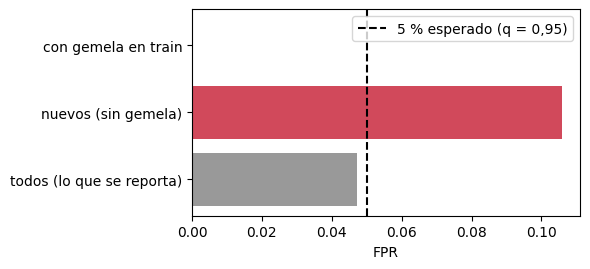

In [75]:
import pickle
modelo_real = RAIZ / "outputs" / "models" / "iforest__por_defecto__seed42__rank0.pkl"
V1 = RAIZ / "data" / "splits"            # versión 1
if not ((V1 / "manifest.json").exists() and modelo_real.exists()):
    print("Falta data/splits o el modelo de linea base: correr antes el pipeline real.")
else:
    with open(modelo_real, "rb") as fh:
        det_real = pickle.load(fh)
    to = common.read_table(common.find_table(V1 / "test_oracle"))
    tr = common.read_table(common.find_table(V1 / "train"))
    F = list(tr.columns)
    en_train = set(pd.util.hash_pandas_object(tr[F], index=False))
    normal_to = to[to["y_true"] == 0]
    repetida = pd.util.hash_pandas_object(normal_to[F], index=False).isin(en_train).to_numpy()
    alarma = det_real.scores(normal_to[F].to_numpy(dtype=np.float32)) > det_real.threshold_
    tabla = pd.DataFrame({
        "flujos normales": [repetida.sum(), (~repetida).sum(), len(repetida)],
        "FPR (falsas alarmas)": [alarma[repetida].mean(), alarma[~repetida].mean(), alarma.mean()],
    }, index=["con gemela en train", "nuevos (sin gemela)", "todos (lo que se reporta)"])
    display(tabla.assign(**{"FPR (falsas alarmas)": tabla["FPR (falsas alarmas)"].map("{:.1%}".format)}))
    fig, ax = plt.subplots(figsize=(6, 2.8))
    ax.barh(tabla.index[::-1], tabla["FPR (falsas alarmas)"][::-1], color=["#999", "#D1495B", "#4C9F70"])
    ax.axvline(0.05, color="k", ls="--", label="5 % esperado (q = 0,95)")
    ax.set_xlabel("FPR"); ax.legend(); plt.tight_layout(); plt.show()

**Cómo leo el resultado:**
- En los normales **con gemela en train**, el modelo casi nunca da falsa alarma: ya los "conoce".
- En los normales **nuevos**, el FPR es alrededor del doble del 5 % que buscaba.
- El FPR reportado (todos juntos) queda cerca del 5 % solo porque más de la mitad son repetidos. En una red real,
  donde los flujos son nuevos, las falsas alarmas serían bastante más.

Es decir: el problema de los duplicados no era teórico, cambiaba los números de la tesis. Por eso hice la v2.

## Qué hice

Corregí el problema en el propio preprocesador, en la versión 2 del experimento:
1. la etapa 01 elimina los flujos repetidos **antes** de partir en train y test, y también los 13 flujos
   distintos que aparecen con etiqueta normal y de ataque a la vez (7 122 filas);
2. la partición 80/20 queda estratificada por tipo de ataque.

Con eso, en la v2 solo el 0,5 % de `val`, el 0,2 % de los normales de `test_final` y el 0,1 % de `test_final`
frente a `test_oracle` son filas idénticas (en la v1 eran 55 %, 56 % y 52 %). Como esto cambia los resultados,
los de la v1 se descartan y la memoria usa los de la v2.

In [76]:
import shutil
shutil.rmtree(TMP, ignore_errors=True)   # limpia la carpeta temporal de los ejemplos
print("Listo. Carpeta temporal borrada.")

Listo. Carpeta temporal borrada.
